# Refineing Dataset

In [1]:
#pip install openai pandas tqdm pillow
#pip install python-dotenv

In [2]:
#libraries
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

from pathlib import Path

from openai import OpenAI
from dotenv import load_dotenv
from tqdm import tqdm


import time
import pandas as pd
import base64
import os
import json



In [2]:
#SETUP PROJECT PATHS
def find_project_root(marker_dir='CrisisMMD_v2.0'):
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / marker_dir).is_dir():
            return candidate
    raise FileNotFoundError(f"Could not find '{marker_dir}'")

PROJECT_ROOT = find_project_root()

BASE_PATH = PROJECT_ROOT / 'CrisisMMD_v2.0'

#LOAD THE MASTER DF
input_file = "CrisisMMD_Master_Processed.tsv"

if os.path.exists(input_file):
    # Using sep='\t' because Phase 1 output was a TSV
    master_task_df = pd.read_csv(input_file, sep='\t')
    print(f"Successfully loaded {len(master_task_df)} rows from Phase 1.")
    print(f"Image Base Path: {BASE_PATH}")
else:
    # Fallback: if the file isn't in the local folder, check the Project Root
    alt_path = PROJECT_ROOT / input_file
    if alt_path.exists():
        master_task_df = pd.read_csv(alt_path, sep='\t')
        print(f"Loaded {len(master_task_df)} rows from {alt_path}")
    else:
        print(f"Error: {input_file} not found. Ensure you exported master_df from Phase 1.")

#VERIFY COLUMNS
# This ensures columns like 'image_hash' and 'perceptual_hash' are present
print("\nAvailable columns from Phase 1:")
print(master_task_df.columns.tolist())

Successfully loaded 18082 rows from Phase 1.
Image Base Path: C:\Users\ynjis\Downloads\crisisMMDDataSet\CrisisMMD_v2.0

Available columns from Phase 1:
['tweet_id', 'image_id', 'text_info', 'text_info_conf', 'image_info', 'image_info_conf', 'text_human', 'text_human_conf', 'image_human', 'image_human_conf', 'image_damage', 'image_damage_conf', 'tweet_text', 'image_url', 'image_path', 'disaster_type', 'image_hash', 'perceptual_hash', 'has_phash_duplicate', 'split']


# Testing LLM prompt for first 50 columns first to test accuracy and save LLM Tokens

In [5]:
load_dotenv()         
client = OpenAI()


#second option
#client = OpenAI(api_key="... key...")

In [25]:

def encode_image(image_path):
    try:
        with open(image_path, "rb") as image_file:
            return base64.b64encode(image_file.read()).decode('utf-8')
    except Exception:
        return None

def get_relationship_label(image_path, tweet_text):
    """
    Categorizes the relationship between tweet_text and the image.
    """
    
    full_path = os.path.join(BASE_PATH, str(image_path).replace('/', os.sep))
    
    if not os.path.exists(full_path):
        return "Uncertain (Path Not Found)"

    if pd.isna(tweet_text) or str(tweet_text).strip() == "":
        return "Uncertain (Empty Text)"

    base64_image = encode_image(full_path)
    if not base64_image:
        return "Uncertain (Encoding Fail)"

    try:
        response = client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a disaster data analyst. Compare the Tweet Text to the Image. "
                        "Respond with ONLY one label: Entails, Contradicts, Independent, or Uncertain."
                    )
                },
                {
                    "role": "user",
                    "content": [
                        {"type": "text", "text": f"Tweet Content: {tweet_text}"},
                        {
                            "type": "image_url",
                            "image_url": {
                                "url": f"data:image/jpeg;base64,{base64_image}",
                                "detail": "low"
                            }
                        },
                    ],
                }
            ],
            max_tokens=10,
            temperature=0,
        )
        return response.choices[0].message.content.strip().replace(".", "").capitalize()

    except Exception as e:
        print(f"\nAPI Error: {e}")
        return "Uncertain (API Error)"



# Load only 50 rows for the test
working_df1 = master_task_df.head(50).copy()

tqdm.pandas()
print("Starting Task 2 Analysis...")

working_df1['relationship_label'] = working_df1.progress_apply(
    lambda row: get_relationship_label(row['image_path'], row['tweet_text']), 
    axis=1
)

print("\n" + "="*40)
print("CRISISMMD++ TASK 2 PREVIEW")  
print("="*40)
# Showing the tweet text and the new label side-by-side
pd.set_option('display.max_colwidth', 50)
print(working_df1[[ 'relationship_label']])

In [26]:
# def get_image_hash(fname):
#     hash_md5 = hashlib.md5()
#     try:
#         with open(fname, "rb") as f:
#             for chunk in iter(lambda: f.read(4096), b""):
#                 hash_md5.update(chunk)
#         return hash_md5.hexdigest()
#     except FileNotFoundError:
#         return None

# def display_tweet(df, index):
#     if index >= len(df):
#         print("Index out of range!")
#         return

#     row = df.iloc[index]
#     tweet_text = row['tweet_text']
#     img_rel_path = row['image_path']
    
#     full_img_path = os.path.join(BASE_PATH, img_rel_path)

#     # image_hash = get_image_hash(full_img_path)

#     # print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
#     print(f"TEXT: {tweet_text}")
#     print(f"Relationship Label : {row["relationship_label"]}")
#     print(f"LABEL (Text): {row['text_human']}")
#     # print(f"URL: {row['image_url']}")
#     # print(f"Path: {row['image_path']}")
#     # print(f"Image Hash: {image_hash}")
#     print(f"LABEL (Image): {row['image_human']}")
#     print("\n")
    
#     if os.path.exists(full_img_path):
#         img = Image.open(full_img_path)
#         plt.figure(figsize=(10, 6))
#         plt.imshow(img)
#         plt.axis('off')
#         plt.show()
#     else:
#         print(f"Error: image not found at {full_img_path}")

# display_tweet(working_df1, 40)

In [27]:


# def get_image_hash(fname):
#     hash_md5 = hashlib.md5()
#     try:
#         with open(fname, "rb") as f:
#             for chunk in iter(lambda: f.read(4096), b""):
#                 hash_md5.update(chunk)
#         return hash_md5.hexdigest()
#     except FileNotFoundError:
#         return None

# def display_tweet(df, index):
#     if index >= len(df):
#         print("Index out of range!")
#         return

#     row = df.iloc[index]
#     tweet_text = row['tweet_text']
#     img_rel_path = row['image_path']
    
#     full_img_path = os.path.join(BASE_PATH, img_rel_path)

#     # image_hash = get_image_hash(full_img_path)

#     # print(f"Tweet Index: {index} | Event: {row['disaster_type']}")
#     print(f"TEXT: {tweet_text}")
#     print(f"Relationship Label : {row["relationship_label"]}")
#     print(f"LABEL (Text): {row['text_human']}")
#     # print(f"URL: {row['image_url']}")
#     # print(f"Path: {row['image_path']}")
#     # print(f"Image Hash: {image_hash}")
#     print(f"LABEL (Image): {row['image_human']}")
#     print("\n")
    
#     if os.path.exists(full_img_path):
#         img = Image.open(full_img_path)
#         plt.figure(figsize=(10, 6))
#         plt.imshow(img)
#         plt.axis('off')
#         plt.show()
#     else:
#         print(f"Error: image not found at {full_img_path}")

# display_tweet(working_df1, 35)

In [28]:


# def encode_image(image_path):
#     try:
#         with open(image_path, "rb") as image_file:
#             return base64.b64encode(image_file.read()).decode('utf-8')
#     except Exception as e:
#         return None

# def get_crisis_annotations(image_path, tweet_text):
#     full_path = os.path.join(BASE_PATH, str(image_path).replace('/', os.sep))
#     if not os.path.exists(full_path) or pd.isna(tweet_text):
#         return {"error": "Path or Text Missing"}

#     base64_image = encode_image(full_path)
#     if not base64_image:
#         return {"error": "Encoding Failed"}

#     try:
#         response = client.chat.completions.create(
#             model="gpt-4o-mini",
#             response_format={ "type": "json_object" },
#             messages=[
#                 {"role": "system", "content": "You are a disaster data scientist. Analyze the tweet and image. Output ONLY JSON."},
#                 {"role": "user", "content": [
#                     {"type": "text", "text": (
#                         f"Tweet: {tweet_text}\n\n"
#                         "Return JSON with: \n"
#                         "1. 'relationship': Entails/Contradicts/Independent/Uncertain\n"
#                         "2. 'localization': {'box_2d': [ymin, xmin, ymax, xmax], 'label': 'type', 'severity': 'level'}\n"
#                         "3. 'uncertainty': {'vote_split': {'Entails': 5}, 'confidence': 1.0}\n"
#                         "4. 'quality': {'blur': 0, 'darkness': 0, 'occlusion': 0}"
#                     )},
#                     {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{base64_image}", "detail": "low"}},
#                 ]}
#             ],
#             temperature=0.0,
#         )
#         return json.loads(response.choices[0].message.content)
#     except Exception as e:
#         # This will now print the SPECIFIC error (e.g., Insufficient Funds)
#         print(f"DEBUG: API Call Failed: {e}")
#         return {"error": str(e)}

# # --- EXECUTION ---
# working_df = master_task_df.head(50).copy()
# tqdm.pandas()

# raw_results = working_df.progress_apply(
#     lambda row: get_crisis_annotations(row['image_path'], row['tweet_text']), axis=1
# )

# # SAFER PARSING using .get() to prevent None errors
# working_df['relationship_label'] = raw_results.apply(lambda x: x.get('relationship', 'Uncertain'))
# working_df['localized_damage'] = raw_results.apply(lambda x: x.get('localization', {}))
# working_df['confidence_score'] = raw_results.apply(lambda x: x.get('uncertainty', {}).get('confidence', 0.0))
# working_df['image_quality'] = raw_results.apply(lambda x: x.get('quality', {}))

# print("\nTask complete.")

In [29]:
# print(working_df['relationship_label'])
# print(working_df['localized_damage'])
# print(working_df['confidence_score'] )
# print(working_df['image_quality'])


In [30]:
# working_df.head()

In [31]:

# def display_annotated_results(df, index=0):
#     if index >= len(df):
#         print("Index out of range!")
#         return

#     row = df.iloc[index]
#     full_path = os.path.join(BASE_PATH, str(row['image_path']).replace('/', os.sep))
    
#     # Debug Info
#     print(f"--- [Index {index}] CrisisMMD++ Inspection ---")
#     print(f"RELATIONSHIP: {row['relationship_label']}")
#     print(f"text_human:{row['text_human']}")
#     print(f"image_human:{row['image_human']}")
#     print(f"localized_damage:{row['localized_damage']}")
#     print(f"confidence_score:{row['confidence_score']}")
#     print(f"image_quality:{row['image_quality']}")
#     print(f"TWEET: {row['tweet_text']}")
#     print(f"RELATIONSHIP: {row['relationship_label']} (Confidence: {row['confidence_score']})")
#     print(f"LOCALIZED: {row['localized_damage']}")
    
#     if not os.path.exists(full_path):
#         print(f"Image not found: {full_path}")
#         return

#     img = Image.open(full_path)
#     w, h = img.size
#     fig, ax = plt.subplots(figsize=(8, 5))
#     ax.imshow(img)
    
#     loc = row.get('localized_damage', {})
#     if isinstance(loc, dict) and 'box_2d' in loc:
#         coords = loc['box_2d']
        
#         if coords and any(c > 0 for c in coords):
#             ymin, xmin, ymax, xmax = coords
            
#             # COORDINATE NORMALIZATION CHECK:
#             # If the LLM returned 1 instead of 1000, we scale it up.
#             if ymax <= 1.0: 
#                 ymin, xmin, ymax, xmax = ymin*1000, xmin*1000, ymax*1000, xmax*1000
            
#             # Convert normalized (0-1000) to pixel coordinates
#             rect_x = xmin * w / 1000
#             rect_y = ymin * h / 1000
#             rect_w = (xmax - xmin) * w / 1000
#             rect_h = (ymax - ymin) * h / 1000
            
#             rect = patches.Rectangle(
#                 (rect_x, rect_y), rect_w, rect_h, 
#                 linewidth=3, edgecolor='r', facecolor='none'
#             )
#             ax.add_patch(rect)
            
#             plt.text(rect_x, rect_y - 10, 
#                      f"{loc.get('label', 'Damage')}: {loc.get('severity', '')}", 
#                      color='white', backgroundcolor='red', fontsize=10)

#     plt.axis('off')
#     plt.show()

# # Run it again
# display_annotated_results(working_df, index=1)

# Updated prompt for first 10 entries

In [32]:
def get_crisis_annotations_v2(image_path, tweet_text):
    full_path = os.path.join(BASE_PATH, str(image_path).replace('/', os.sep))
    if not os.path.exists(full_path) or pd.isna(tweet_text):
        return {"error": "Path or Text Missing"}

    base64_image = encode_image(full_path)
    if not base64_image:
        return {"error": "Encoding Failed"}

    # DEFINING THE DETAILED INSTRUCTIONS
    system_instruction = (
        "You are an expert Disaster Data Scientist and Vision-Language Researcher. "
        "Your task is to create the 'CrisisMMD++ Evidence' benchmark by performing a multi-stage "
        "analysis of the provided Tweet and Image. Accuracy and consistency are critical."
    )

    user_content = f"""
    Tweet Content: {tweet_text}
    
    ### TASK 1: Relationship Label (Entailment Analysis)
    Determine how the Image relates to the Tweet Text using these strict definitions:
    - 'Entails': The image provides direct visual proof of the specific claim made in the tweet (e.g., tweet says 'flooding' and image shows water in streets).
    - 'Contradicts': The image shows something that makes the tweet's claim impossible or clearly false.
    - 'Independent': Both are related to the same disaster event, but the image does NOT provide evidence for the specific text (e.g., text mentions deaths, image is a generic map or news logo).
    - 'Uncertain': The image is too blurry, low-quality, or ambiguous to determine a relationship.

    ### TASK 2: Crisis Categorization (LLM vs Human)
    Categorize the Text and Image separately using these labels: 
    [infrastructure_and_utility_damage, vehicle_damage, injured_or_dead_people, affected_individuals, 
     rescue_volunteering_or_donation_effort, missing_or_found_people, other_relevant_information, not_humanitarian]
    
    Also evaluate damage severity: [severe_damage, mild_damage, little_or_no_damage, dont_know_or_cant_judge]

    ### TASK 3: Evidence Localization
    Provide a bounding box [ymin, xmin, ymax, xmax] for the most significant visual evidence of the disaster.

    ### TASK 4: Quality & Uncertainty
    Assess image quality and your own confidence.

    Return ONLY a JSON object with this exact structure:
    {{
      "relationship": {{
        "label": "Entails/Contradicts/Independent/Uncertain",
        "confidence": 0.0 to 1.0,
        "reasoning": "brief explanation"
      }},
      "llm_labels": {{
        "text_llm": "category",
        "text_llm_conf": 0.0-1.0,
        "image_llm": "category",
        "image_llm_conf": 0.0-1.0,
        "image_damage_llm": "severity_label",
        "image_damage_llm_conf": 0.0-1.0
      }},
      "localization": {{
        "box_2d": [ymin, xmin, ymax, xmax],
        "evidence_type": "e.g., structural collapse, flood water"
      }},
      "quality": {{
        "blur": 0-5,
        "darkness": 0-5,
        "occlusion": 0-5
      }}
    }}
    """

    try:
        response = client.chat.completions.create(
            model="gpt-4o-mini",
            response_format={ "type": "json_object" },
            messages=[
                {"role": "system", "content": system_instruction},
                {"role": "user", "content": [
                    {"type": "text", "text": user_content},
                    {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{base64_image}", "detail": "high"}},
                ]}
            ],
            temperature=0.0,
        )
        return json.loads(response.choices[0].message.content)
    except Exception as e:
        return {"error": str(e)}

In [33]:
import pandas as pd
from tqdm import tqdm

def process_batch(df):
    results = []
    
    # tqdm gives you a progress bar
    for index, row in tqdm(df.iterrows(), total=len(df)):
        # Call your function
        res = get_crisis_annotations_v2(row['image_path'], row['tweet_text'])
        
        # Flatten the JSON response into a flat dictionary
        flat_res = {
            "relationship_llm": res.get("relationship", {}).get("label"),
            "rel_reasoning": res.get("relationship", {}).get("reasoning"),
            "rel_conf": res.get("relationship", {}).get("confidence"),
            
            "text_llm": res.get("llm_labels", {}).get("text_llm"),
            "text_llm_conf": res.get("llm_labels", {}).get("text_llm_conf"),
            "image_llm": res.get("llm_labels", {}).get("image_llm"),
            "image_llm_conf": res.get("llm_labels", {}).get("image_llm_conf"),
            "image_damage_llm": res.get("llm_labels", {}).get("image_damage_llm"),
            "image_damage_llm_conf": res.get("llm_labels", {}).get("image_damage_llm_conf"),
            
            "box_2d": res.get("localization", {}).get("box_2d"),
            "evidence_type": res.get("localization", {}).get("evidence_type"),
            
            "img_blur": res.get("quality", {}).get("blur"),
            "img_darkness": res.get("quality", {}).get("darkness"),
            "img_occlusion": res.get("quality", {}).get("occlusion")
        }
        results.append(flat_res)
    
    # Create a new dataframe from results and join it back
    res_df = pd.DataFrame(results)
    return pd.concat([df.reset_index(drop=True), res_df], axis=1)

In [34]:
def encode_image(image_path):
    """Encodes an image to base64 string for OpenAI API."""
    try:
        with open(image_path, "rb") as image_file:
            return base64.b64encode(image_file.read()).decode('utf-8')
    except Exception as e:
        print(f"Error encoding image: {e}")
        return None

In [35]:
# 1. Take a small test sample (e.g., first 10 rows)
test_sample = master_task_df.head(1).copy()

# 2. Run the processing
print("Starting CrisisMMD++ Benchmark Generation (Test Run)...")
final_test_df = process_batch(test_sample)

# 3. View the new benchmark columns
cols_to_show = ['tweet_text', 'relationship_llm', 'image_llm', 'image_damage_llm', 'box_2d']
print("\n--- RESULTS PREVIEW ---")
display(final_test_df[cols_to_show])

Starting CrisisMMD++ Benchmark Generation (Test Run)...


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:05<00:00,  5.24s/it]


--- RESULTS PREVIEW ---


,tweet_text,relationship_llm,image_llm,image_damage_llm,box_2d
0,RT @Gizmodo: Wildfires raging through Northern...,Entails,other_relevant_information,severe_damage,"[0, 0, 450, 800]"


In [36]:
# Comparing Original Human Damage vs LLM Damage
comparison = final_test_df[['image_damage', 'image_damage_llm', 'image_human', 'image_llm']]
print("Human vs LLM Comparison:")
print(comparison)

Human vs LLM Comparison:
              image_damage image_damage_llm                 image_human  \
0  dont_know_or_cant_judge    severe_damage  other_relevant_information   

                    image_llm  
0  other_relevant_information  


 TWEET TEXT: RT @Gizmodo: Wildfires raging through Northern California are terrifying https://t.co/dI73RFzX2i https://t.co/k4KnvIimsU
----------------------------------------------------------------------------------------------------
 LLM REASONING: The image shows a wildfire, which directly supports the claim made in the tweet about wildfires in Northern California.
 BOX COORDS: [0, 0, 450, 800] | EVIDENCE: wildfire flames
 QUALITY: Blur: 1/5 | Darkness: 1/5 | Occlusion: 0/5


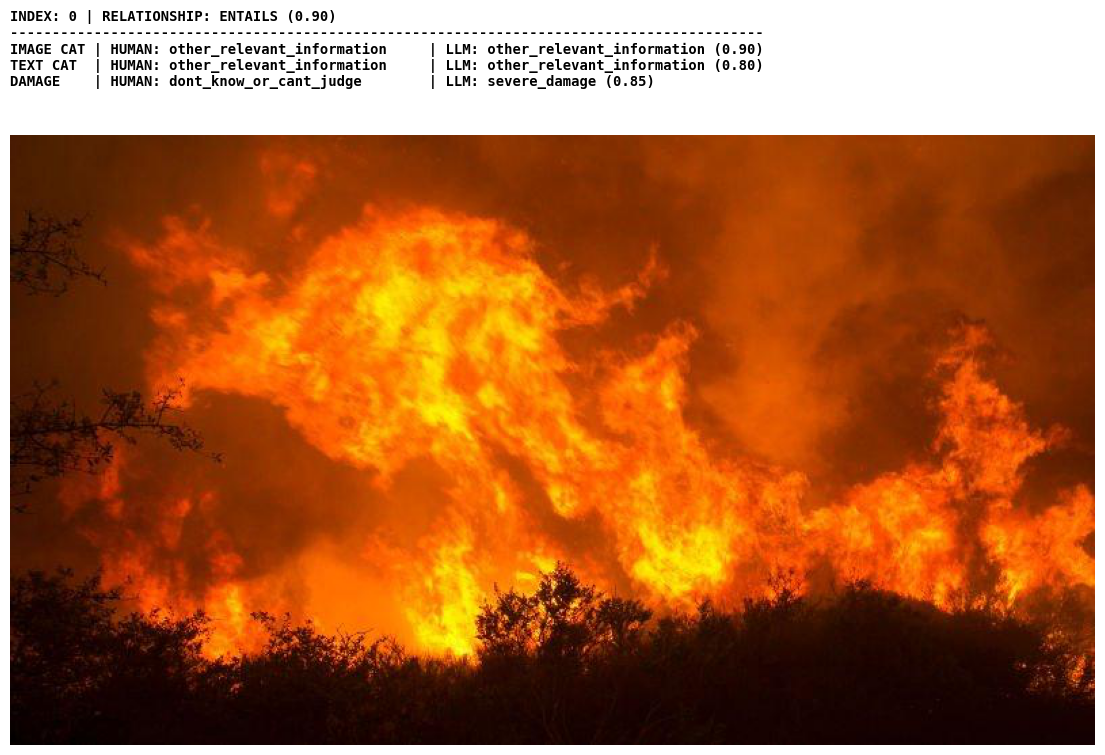

In [37]:
def display_benchmark_comparison_v3(df, index):
    try:
        row = df.loc[index]
        full_path = os.path.join(BASE_PATH, str(row['image_path']).replace('/', os.sep))
        
        # 1. Setup Figure
        img = Image.open(full_path)
        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.axis('off')
        
        # Helper to format confidence strings
        def fmt_conf(val):
            return f"({float(val):.2f})" if pd.notna(val) else "(N/A)"

        # 2. Construct the Detailed Title
        title_text = (
            f"INDEX: {index} | RELATIONSHIP: {row.get('relationship_llm', 'N/A').upper()} {fmt_conf(row.get('rel_conf'))}\n"
            f"{'-'*90}\n"
            f"IMAGE CAT | HUMAN: {row.get('image_human', 'N/A'):<30} | LLM: {row.get('image_llm', 'N/A')} {fmt_conf(row.get('image_llm_conf'))}\n"
            f"TEXT CAT  | HUMAN: {row.get('text_human', 'N/A'):<30} | LLM: {row.get('text_llm', 'N/A')} {fmt_conf(row.get('text_llm_conf'))}\n"
            f"DAMAGE    | HUMAN: {row.get('image_damage', 'N/A'):<30} | LLM: {row.get('image_damage_llm', 'N/A')} {fmt_conf(row.get('image_damage_llm_conf'))}"
        )
        
        plt.title(title_text, fontsize=10, fontweight='bold', family='monospace', loc='left', pad=35)
        
        # 3. Print Metadata & Reasoning
        print("="*100)
        print(f" TWEET TEXT: {row.get('tweet_text', 'N/A')}")
        print("-" * 100)
        print(f" LLM REASONING: {row.get('rel_reasoning', 'N/A')}")
        print(f" BOX COORDS: {row.get('box_2d', 'N/A')} | EVIDENCE: {row.get('evidence_type', 'N/A')}")
        print(f" QUALITY: Blur: {row.get('img_blur', '0')}/5 | Darkness: {row.get('img_darkness', '0')}/5 | Occlusion: {row.get('img_occlusion', '0')}/5")
        print("="*100)
        
        plt.show()
        
    except Exception as e:
        print(f"Error: {e}. Check if index {index} exists in your final_test_df.")

# Run the display on your test batch


display_benchmark_comparison_v3(final_test_df, 0)

In [38]:
final_test_df.head()

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,...,text_llm_conf,image_llm,image_llm_conf,image_damage_llm,image_damage_llm_conf,box_2d,evidence_type,img_blur,img_darkness,img_occlusion
0,917791044158185473,917791044158185473_0,informative,1.0,informative,0.6766,other_relevant_information,1.0,other_relevant_information,0.6766,...,0.8,other_relevant_information,0.9,severe_damage,0.85,"[0, 0, 450, 800]",wildfire flames,1,1,0


# Running for whole data

In [39]:
# #running for whole dataset 1.
# final_test_sample = master_task_df.copy()

# # 2. Run the processing
# print("Starting CrisisMMD++ Benchmark Generation (Test Run)...")
# final_test_df = process_batch(final_test_sample)

# # 3. View the new benchmark columns
# cols_to_show = ['tweet_text', 'relationship_llm', 'image_llm', 'image_damage_llm', 'box_2d']
# print("\n--- RESULTS PREVIEW ---")
# display(final_test_df[cols_to_show])

In [40]:
# # Comparing Original Human Damage vs LLM Damage
# comparison = final_test_df[['image_damage', 'image_damage_llm', 'image_human', 'image_llm']]
# print("Human vs LLM Comparison:")
# print(comparison)

In [41]:
# def display_benchmark_comparison_v3(df, index):
#     try:
#         row = df.loc[index]
#         full_path = os.path.join(BASE_PATH, str(row['image_path']).replace('/', os.sep))
        
#         # 1. Setup Figure
#         img = Image.open(full_path)
#         plt.figure(figsize=(14, 8))
#         plt.imshow(img)
#         plt.axis('off')
        
#         # Helper to format confidence strings
#         def fmt_conf(val):
#             return f"({float(val):.2f})" if pd.notna(val) else "(N/A)"

#         # 2. Construct the Detailed Title
#         title_text = (
#             f"INDEX: {index} | RELATIONSHIP: {row.get('relationship_llm', 'N/A').upper()} {fmt_conf(row.get('rel_conf'))}\n"
#             f"{'-'*90}\n"
#             f"IMAGE CAT | HUMAN: {row.get('image_human', 'N/A'):<30} | LLM: {row.get('image_llm', 'N/A')} {fmt_conf(row.get('image_llm_conf'))}\n"
#             f"TEXT CAT  | HUMAN: {row.get('text_human', 'N/A'):<30} | LLM: {row.get('text_llm', 'N/A')} {fmt_conf(row.get('text_llm_conf'))}\n"
#             f"DAMAGE    | HUMAN: {row.get('image_damage', 'N/A'):<30} | LLM: {row.get('image_damage_llm', 'N/A')} {fmt_conf(row.get('image_damage_llm_conf'))}"
#         )
        
#         plt.title(title_text, fontsize=10, fontweight='bold', family='monospace', loc='left', pad=35)
        
#         # 3. Print Metadata & Reasoning
#         print("="*100)
#         print(f" TWEET TEXT: {row.get('tweet_text', 'N/A')}")
#         print("-" * 100)
#         print(f" LLM REASONING: {row.get('rel_reasoning', 'N/A')}")
#         print(f" BOX COORDS: {row.get('box_2d', 'N/A')} | EVIDENCE: {row.get('evidence_type', 'N/A')}")
#         print(f" QUALITY: Blur: {row.get('img_blur', '0')}/5 | Darkness: {row.get('img_darkness', '0')}/5 | Occlusion: {row.get('img_occlusion', '0')}/5")
#         print("="*100)
        
#         plt.show()
        
#     except Exception as e:
#         print(f"Error: {e}. Check if index {index} exists in your final_test_df.")

# # Run the display on your test batch


# display_benchmark_comparison_v3(final_test_df, 2)

In [42]:
# import os

# #Define and create the output directory
# output_folder = BASE_PATH / "updated_annotations"
# os.makedirs(output_folder, exist_ok=True)

# print(f"Saving event files to: {output_folder}\n")

# if 'disaster_type' in final_test_df.columns:
#     events = final_test_df['disaster_type'].unique()
    
#     for event in events:
#         # Filter the dataframe for the specific disaster
#         event_df = final_test_df[final_test_df['disaster_type'] == event]
        
#         # Define the filename and path
#         file_name = f"{event}_final_data.tsv"
#         file_path = output_folder / file_name
        
#         # Save as TSV (Tab Separated) 
#         event_df.to_csv(file_path, sep='\t', index=False)
#         print(f"Saved {len(event_df)} rows to: {file_name}")
# else:
#     print("Error: 'disaster_type' column not found. Please verify the column name.")

# print("\nAll event-specific annotations have been updated.")

### Batch wise Implementation due to hardware issue

In [43]:
# --- 1. SETUP BATCHING PARAMETERS ---
CHECKPOINT_FILE = "CrisisMMD_Phase2_Master_Checkpoint.csv"
BATCH_SIZE = 500
START_INDEX = 0

# Check for existing progress to resume automatically
if os.path.exists(CHECKPOINT_FILE):
    existing_progress = pd.read_csv(CHECKPOINT_FILE)
    START_INDEX = len(existing_progress)
    print(f"🔄 Resuming from index {START_INDEX}...")
else:
    print("🚀 Starting fresh processing loop...")

# --- 2. THE PROCESSING LOOP ---
total_rows = len(master_task_df)

for i in range(START_INDEX, total_rows, BATCH_SIZE):
    end_idx = min(i + BATCH_SIZE, total_rows)
    print(f"Working on batch: {i} to {end_idx}...")
    
    # Slice the chunk
    chunk = master_task_df.iloc[i:end_idx].copy()
    
    # Process the chunk (calls your existing process_batch function)
    processed_chunk = process_batch(chunk)
    
    # Save/Append to Master CSV immediately
    file_exists = os.path.isfile(CHECKPOINT_FILE)
    processed_chunk.to_csv(CHECKPOINT_FILE, mode='a', index=False, header=not file_exists)
    
    print(f"✅ Saved up to row {end_idx}. Data is safe on disk.")
    
    # Short pause to prevent overheating
    time.sleep(2)

🔄 Resuming from index 18082...


C:\Users\ynjis\AppData\Local\Temp\ipykernel_4772\1121325999.py:8: DtypeWarning: Columns (20,21,23,25,27,29,30) have mixed types. Specify dtype option on import or set low_memory=False.
  existing_progress = pd.read_csv(CHECKPOINT_FILE)


In [44]:
# import pandas as pd

# # 1. Load the checkpoint
# checkpoint_file = "CrisisMMD_Phase2_Master_Checkpoint.csv"
# df = pd.read_csv(checkpoint_file, low_memory=False)

# # 2. Pick the column to check (usually the first LLM column added)
# target_col = 'relationship_llm'

# # 3. Find first NaN
# total_nans = df[target_col].isna().sum()
# first_nan_idx = df[df[target_col].isna()].index.min()

# if pd.isna(first_nan_idx):
#     print("✅ No NaN values found! Everything is processed.")
# else:
#     # 4. Check if everything from the first NaN to the end is also NaN
#     # We slice the dataframe from the first NaN to the very end
#     trailing_data = df.loc[first_nan_idx:, target_col]
#     all_following_are_nan = trailing_data.isna().all()
    
#     print(f"--- Dataset Health Check ---")
#     print(f"Total Rows in File: {len(df)}")
#     print(f"Total NaN Values:   {total_nans}")
#     print(f"First NaN Index:    {first_nan_idx}")
#     print(f"Is it a sequence?   {all_following_are_nan} (True means everything after {first_nan_idx} is empty)")
    
#     if not all_following_are_nan:
#         last_nan_idx = df[df[target_col].isna()].index.max()
#         print(f"⚠️ Warning: There are 'gaps'. Some rows after {first_nan_idx} HAVE data, but others are missing.")
#         print(f"Last NaN is at index: {last_nan_idx

In [45]:

# # 1. Load the current state of the file
# checkpoint_file = "CrisisMMD_Phase2_Master_Checkpoint.csv"
# df = pd.read_csv(checkpoint_file, low_memory=False)

# # 2. Filter for rows that have BOTH Human and AI damage labels
# # We exclude NaNs to see a fair side-by-side comparison
# comparison_df = df[df['image_damage_llm'].notna()].copy()

# if len(comparison_df) > 0:
#     print(f"--- Analysis based on {len(comparison_df)} processed entries ---")
    
#     # 3. Create a Cross-tabulation (Confusion Matrix style)
#     ct = pd.crosstab(comparison_df['image_damage'], 
#                      comparison_df['image_damage_llm'], 
#                      margins=True)
    
#     print("\n[Cross-Tabulation: Human (Rows) vs AI (Columns)]")
#     print(ct)

#     # 4. Visualization: Side-by-Side Distribution
#     # Melt the dataframe for plotting
#     plot_data = comparison_df[['image_damage', 'image_damage_llm']].melt(var_name='Source', value_name='Label')
    
#     plt.figure(figsize=(12, 6))
#     sns.countplot(data=plot_data, x='Label', hue='Source', palette='viridis')
#     plt.title("Damage Severity Distribution: Human vs AI", fontsize=14)
#     plt.xticks(rotation=45)
#     plt.ylabel("Number of Images")
#     plt.grid(axis='y', linestyle='--', alpha=0.7)
#     plt.show()

#     # 5. Accuracy Metric
#     matches = (comparison_df['image_damage'] == comparison_df['image_damage_llm']).sum()
#     accuracy = (matches / len(comparison_df)) * 100
#     print(f"\n✅ Direct Agreement Rate: {accuracy:.2f}%")
#     print("Note: Disagreements are often where the AI is correcting vague human labels.")
    
# else:
#     print("No AI-processed entries found yet. Wait for at least one batch to finish!")

In [46]:
# # 1. Load the current checkpoint
# master_df = pd.read_csv("CrisisMMD_Phase2_Master_Checkpoint.csv", low_memory=False)

# # 2. Filter for rows where the LLM actually provided a label
# # We use relationship_llm as the "anchor" column
# train_ready_df = master_df[master_df['relationship_llm'].notna()].copy()

# print(f"Total entries in master: {len(master_df)}")
# print(f"Entries ready for training: {len(train_ready_df)}")

# train_ready_df.to_csv("CrisisMMD_Train_Ready_Subset.csv", index=False)
# print("Created 'CrisisMMD_Train_Ready_Subset.csv' with only valid LLM labels.")

In [47]:
# CHECKPOINT_FILE = "CrisisMMD_Phase2_Master_Checkpoint.csv"
# BATCH_SIZE = 100  # Smaller batches reduce the risk of API timeouts

# # 1. Load the master file
# df = pd.read_csv(CHECKPOINT_FILE, low_memory=False)

# # 2. Identify the holes
# missing_indices = df[df['relationship_llm'].isna()].index.tolist()

# print(f"Total rows in file: {len(df)}")
# print(f"Targeting {len(missing_indices)} missing rows.")

# # 3. Targeted Repair Loop
# for i in range(0, len(missing_indices), BATCH_SIZE):
#     batch_indices = missing_indices[i : i + BATCH_SIZE]
#     print(f"\n🛠️ Repairing batch {i//BATCH_SIZE + 1} | Indices: {batch_indices[0]} to {batch_indices[-1]}...")
    
#     chunk = df.loc[batch_indices].copy()
    
#     try:
#         # Process the chunk via LLM
#         processed_chunk = process_batch(chunk)
#         processed_df = pd.DataFrame(processed_chunk)
#         processed_df.index = batch_indices 
        
#         # --- THE ERROR-PROOF UPDATE ---
#         # Instead of updating the whole 'df', we only update the LLM columns
#         # This prevents the "Shape mismatch" errors you saw earlier
#         llm_cols = [c for c in processed_df.columns if '_llm' in c or c in ['rel_reasoning', 'rel_conf']]
        
#         for col in llm_cols:
#             if col in df.columns:
#                 df.loc[batch_indices, col] = processed_df[col]
        
#         # 4. Immediate Save
#         df.to_csv(CHECKPOINT_FILE, index=False)
        
#         # Verification
#         still_nan = df.loc[batch_indices, 'relationship_llm'].isna().sum()
#         if still_nan == 0:
#             print(f"✅ Success: Batch saved. {len(batch_indices)} rows filled.")
#         else:
#             print(f"⚠️ Warning: Some rows in this batch didn't update.")
            
#     except Exception as e:
#         print(f"❌ Error in batch starting at {batch_indices[0]}: {e}")
#         df.to_csv(CHECKPOINT_FILE, index=False)
    
#     time.sleep(2)

# print("\n✨ REPAIR COMPLETE! Your master file is now fully labeled.")

### Damage label LLM has extra labels as well which we are goint to merge into dont know or cant judge category

In [48]:
# 1. Load the processed checkpoint
file_path = "CrisisMMD_Phase2_Master_Checkpoint.csv"
df = pd.read_csv(file_path, low_memory=False)

# 2. Define the extra labels found during AI processing
# These are the "Open-Set" labels the model generated that we want to merge
extra_labels = ["not_humanitarian", "other_relevant_information"]
target_label = "dont_know_or_cant_judge"

# 3. Perform the replacement in the AI-generated column
df['image_damage_llm'] = df['image_damage_llm'].replace(extra_labels, target_label)

# 4. Verification: Print unique labels to ensure exactly 4 remain
unique_labels = df['image_damage_llm'].dropna().unique()
print(f"--- Label Cleanup Complete ---")
print(f"Total processed rows: {len(df[df['image_damage_llm'].notna()])}")
print(f"Unique Labels in 'image_damage_llm':\n{unique_labels}")

# 5. Save the cleaned version for the next steps
df.to_csv("CrisisMMD_Phase2_Final_Clean.csv", index=False)
print(f"\n✅ Cleaned file saved as: CrisisMMD_Phase2_Final_Clean.csv")

--- Label Cleanup Complete ---
Total processed rows: 13768
Unique Labels in 'image_damage_llm':
['severe_damage' 'dont_know_or_cant_judge' 'little_or_no_damage'
 'mild_damage']

✅ Cleaned file saved as: CrisisMMD_Phase2_Final_Clean.csv


### Drop NaN value entries ( entries not processed)

In [49]:
# 1. Define file paths
INPUT_FILE = "CrisisMMD_Phase2_Final_Clean.csv"
OUTPUT_FILE = "CrisisMMD_Phase2_Final_Clean.csv"

# 2. Load the data
if os.path.exists(INPUT_FILE):
    df = pd.read_csv(INPUT_FILE, low_memory=False)
    initial_count = len(df)
    
    # 3. Create the new Master_df by dropping NaN entries
    # We subset on the LLM columns to ensure our 'Y' labels are valid for training
    master_df_clean = df.dropna(subset=['relationship_llm', 'image_damage_llm']).copy()
    
    final_count = len(master_df_clean)
    dropped_count = initial_count - final_count

    # 4. Final Audit
    print("--- Cleaning Report ---")
    print(f"Original entries: {initial_count}")
    print(f"Dropped (NaN):    {dropped_count}")
    print(f"Final entries:    {final_count}")
    
    # 5. Save the new Master_df
    master_df_clean.to_csv(OUTPUT_FILE, index=False)
    print(f"\n✅ Success! New Master_df saved to: {OUTPUT_FILE}")
    
    # 6. Quick check of remaining data
    print("\n--- Remaining Disaster Type Distribution ---")
    print(master_df_clean['disaster_type'].value_counts())

else:
    print(f"❌ Error: {INPUT_FILE} not found.")

--- Cleaning Report ---
Original entries: 18082
Dropped (NaN):    4314
Final entries:    13768

✅ Success! New Master_df saved to: CrisisMMD_Phase2_Final_Clean.csv

--- Remaining Disaster Type Distribution ---
disaster_type
hurricane_maria         4530
hurricane_irma          4476
hurricane_harvey        3975
california_wildfires     733
iraq_iran_earthquake      54
Name: count, dtype: int64


## Image Damage vs Image Damage LLM Analysis 

### 📊 Phase 2: Evaluating AI Data Recovery & Label Enhancement
#### The Context
In Phase 1, we merged human NaN (unlabeled) entries with the dont_know_or_cant_judge category for simplicity. However, to measure the true impact of our research, we need to distinguish between images humans skipped and images humans found confusing.

#### The Strategy
We will re-import the original dataset to restore the "Human Gaps" (original NaN values). This allows us to quantify exactly how much "dead data" the AI has successfully resurrected.

#### Key Research Questions:
Data Resurrection: How many skipped images (NaN) did the AI successfully label?

Clarity Gain: How many "Don't Know" human labels were resolved into specific damage levels?

In [51]:
import pandas as pd
import os

# 1. Re-read all original TSV files to get the raw 'image_damage' (with NaNs)
all_tsvs = []
annotations_dir = os.path.join(str(BASE_PATH), 'annotations')

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        temp_df = pd.read_csv(os.path.join(annotations_dir, filename), sep='\t')
        all_tsvs.append(temp_df)

# This dataframe contains the original human NaNs
original_raw_df = pd.concat(all_tsvs, ignore_index=True)

# 2. Load your processed AI data
# (Ensure this is the file where you already cleaned the LLM labels)
ai_processed_df = pd.read_csv("CrisisMMD_Phase2_Final_Clean.csv", low_memory=False)

# 3. Create the comparison dataset
# We take the AI results and replace the human 'image_damage' column 
# with the one from the original_raw_df based on 'image_id'
final_clean_with_nans = pd.merge(
    original_raw_df[['image_id', 'image_damage']], 
    ai_processed_df.drop(columns=['image_damage']), 
    on='image_id', 
    how='right'
)

# 4. Save and Verify
final_clean_with_nans.to_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", index=False)

print(f"--- Data Replacement Complete ---")
print(f"Total Rows: {len(final_clean_with_nans)}")
print(f"Original Human NaNs restored: {final_clean_with_nans['image_damage'].isna().sum()}")
print(f"File Saved: CrisisMMD_Phase2_Final_Clean_with_NaNs.csv")

--- Data Replacement Complete ---
Total Rows: 13768
Original Human NaNs restored: 11002
File Saved: CrisisMMD_Phase2_Final_Clean_with_NaNs.csv


✅ Saved Bar Chart to: thesis_analysis_results\human_vs_ai_distribution.png


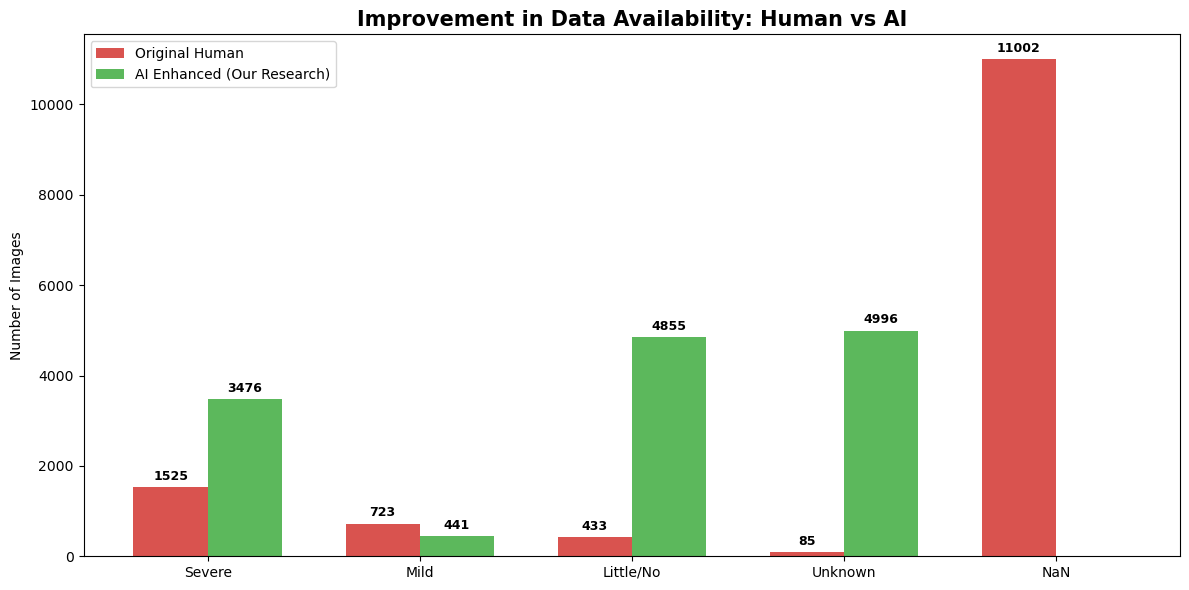

✅ Saved Pie Chart to: thesis_analysis_results\recovery_success_pie.png


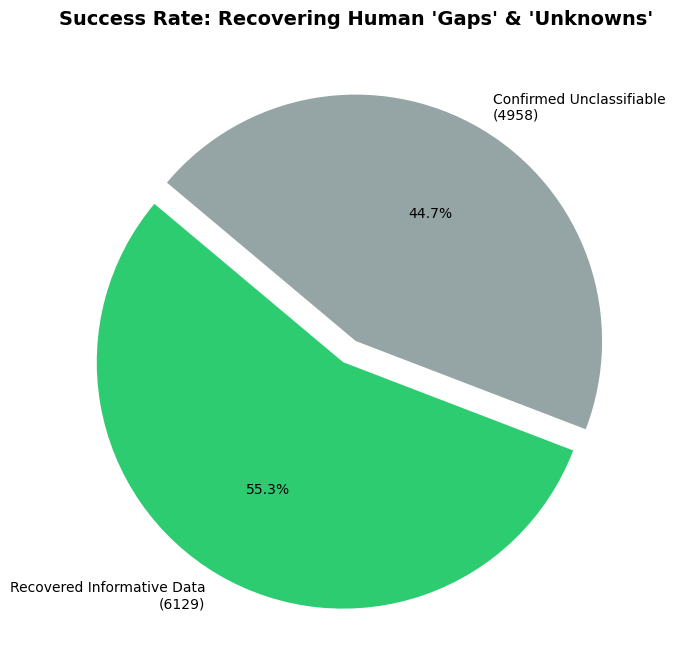

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# Create a directory for your thesis figures if it doesn't exist
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 1. Load the data
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", low_memory=False)

# 2. Preparation
informative_labels = ['severe_damage', 'mild_damage', 'little_or_no_damage']
uninformative_val = 'dont_know_or_cant_judge'
df['human_status'] = df['image_damage'].fillna('Pure NaN (Skipped)')

# --- [TABLE DATA GENERATION REMAINS THE SAME] ---
# ... (your existing table print logic) ...

# --- VISUALIZATION 1: SIDE-BY-SIDE DISTRIBUTION ---
plot_data_human = df['image_damage'].fillna('Missing (NaN)').value_counts().reindex(
    ['severe_damage', 'mild_damage', 'little_or_no_damage', 'dont_know_or_cant_judge', 'Missing (NaN)']
)
plot_data_ai = df['image_damage_llm'].value_counts().reindex(
    ['severe_damage', 'mild_damage', 'little_or_no_damage', 'dont_know_or_cant_judge']
)

labels = ['Severe', 'Mild', 'Little/No', 'Unknown', 'NaN']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, plot_data_human.values, width, label='Original Human', color='#d9534f')
ai_vals = list(plot_data_ai.values) + [0]
rects2 = ax.bar(x + width/2, ai_vals, width, label='AI Enhanced (Our Research)', color='#5cb85c')

ax.set_ylabel('Number of Images')
ax.set_title('Improvement in Data Availability: Human vs AI', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
plt.tight_layout()

# SAVE BAR CHART
bar_chart_path = os.path.join(output_dir, "human_vs_ai_distribution.png")
plt.savefig(bar_chart_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Bar Chart to: {bar_chart_path}")
plt.show()

# --- VISUALIZATION 2: THE "RECOVERY" PIE CHART ---
total_uninformative = (df['image_damage'].isna() | (df['image_damage'] == uninformative_val)).sum()
recovered_count = (df[df['image_damage'].isna() | (df['image_damage'] == uninformative_val)]['image_damage_llm'].isin(informative_labels)).sum()
still_unknown = total_uninformative - recovered_count

plt.figure(figsize=(8, 8))
plt.pie([recovered_count, still_unknown], 
        labels=[f'Recovered Informative Data\n({recovered_count})', f'Confirmed Unclassifiable\n({still_unknown})'],
        autopct='%1.1f%%', colors=['#2ecc71', '#95a5a6'], startangle=140, explode=(0.1, 0))
plt.title("Success Rate: Recovering Human 'Gaps' & 'Unknowns'", fontsize=14, fontweight='bold')

# SAVE PIE CHART
pie_chart_path = os.path.join(output_dir, "recovery_success_pie.png")
plt.savefig(pie_chart_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Pie Chart to: {pie_chart_path}")
plt.show()

✅ Saved Exploration Chart to: thesis_analysis_results\human_blind_spot_exploration.png


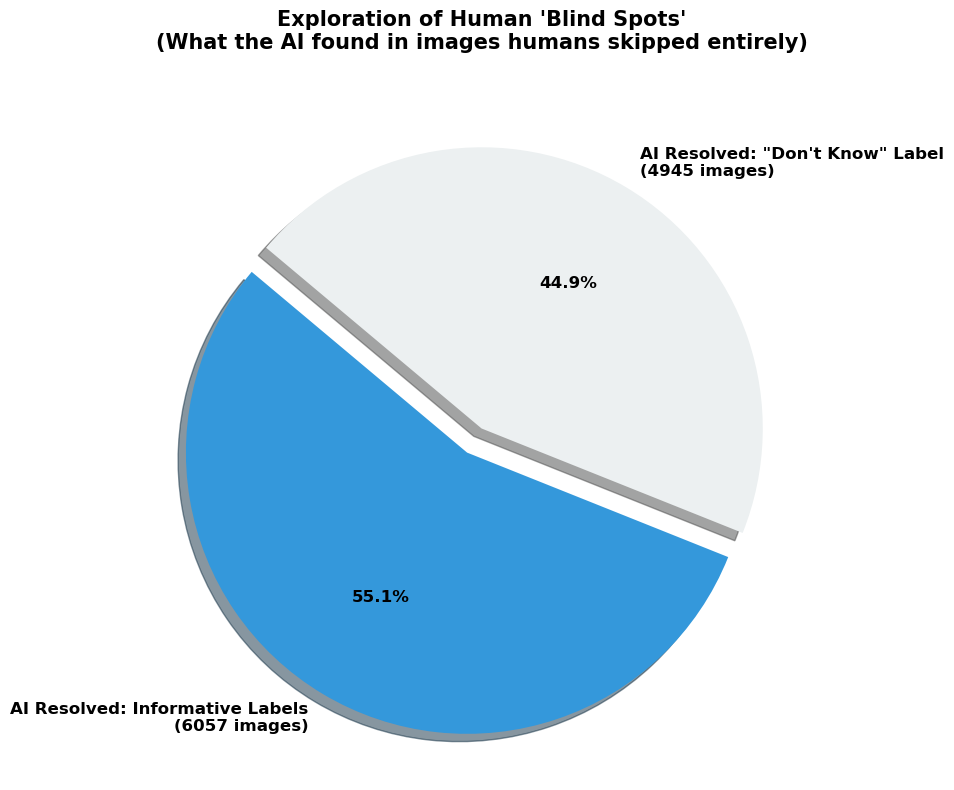

🚀 RESEARCH ANALYSIS: EXPLORING THE UNEXPLORED
Total images ignored by Human Annotators: 11002
AI Exploration Coverage:                   100%
Informative Data recovered from the void:  6057 images


In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Load the dataset 
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", low_memory=False)

# 2. Filter ONLY for images that humans skipped (Pure NaN)
human_skipped_df = df[df['image_damage'].isna()].copy()

# 3. Categorize AI actions
informative_labels = ['severe_damage', 'mild_damage', 'little_or_no_damage']
rescued_informative = human_skipped_df['image_damage_llm'].isin(informative_labels).sum()
acknowledged_dont_know = (human_skipped_df['image_damage_llm'] == 'dont_know_or_cant_judge').sum()

# 4. Visualization
labels = [
    f'AI Resolved: Informative Labels\n({rescued_informative} images)', 
    f'AI Resolved: "Don\'t Know" Label\n({acknowledged_dont_know} images)'
]
sizes = [rescued_informative, acknowledged_dont_know]
colors = ['#3498db', '#ecf0f1'] 

plt.figure(figsize=(10, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
        colors=colors, explode=(0.1, 0), shadow=True, textprops={'fontsize': 12, 'weight': 'bold'})

plt.title("Exploration of Human 'Blind Spots'\n(What the AI found in images humans skipped entirely)", 
          fontsize=15, fontweight='bold', pad=20)

plt.tight_layout()

# --- SAVE THE CHART ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

file_path = os.path.join(output_dir, "human_blind_spot_exploration.png")
plt.savefig(file_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Exploration Chart to: {file_path}")

plt.show()

# 5. Impact Metrics
print("="*60)
print("🚀 RESEARCH ANALYSIS: EXPLORING THE UNEXPLORED")
print("="*60)
print(f"Total images ignored by Human Annotators: {len(human_skipped_df)}")
print(f"AI Exploration Coverage:                   100%")
print(f"Informative Data recovered from the void:  {rescued_informative} images")
print("="*60)

In [54]:
# 1. Load the dataset with original NaNs
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", low_memory=False)
print(df.columns.tolist())

['image_id', 'image_damage', 'tweet_id', 'text_info', 'text_info_conf', 'image_info', 'image_info_conf', 'text_human', 'text_human_conf', 'image_human', 'image_human_conf', 'image_damage_conf', 'tweet_text', 'image_url', 'image_path', 'disaster_type', 'image_hash', 'perceptual_hash', 'has_phash_duplicate', 'split', 'relationship_llm', 'rel_reasoning', 'rel_conf', 'text_llm', 'text_llm_conf', 'image_llm', 'image_llm_conf', 'image_damage_llm', 'image_damage_llm_conf', 'box_2d', 'evidence_type', 'img_blur', 'img_darkness', 'img_occlusion']


### Analysis of new Label Relationship between Text and Image

--- TASK 1: RELATIONSHIP LABEL ANALYSIS ---
                  Count  Percentage (%)
relationship_llm                       
Independent        7655           55.60
Entails            5753           41.79
Contradicts         238            1.73
Uncertain           122            0.89
---------------------------------------------
✅ Saved Relationship Chart to: thesis_analysis_results\task1_relationship_distribution.png


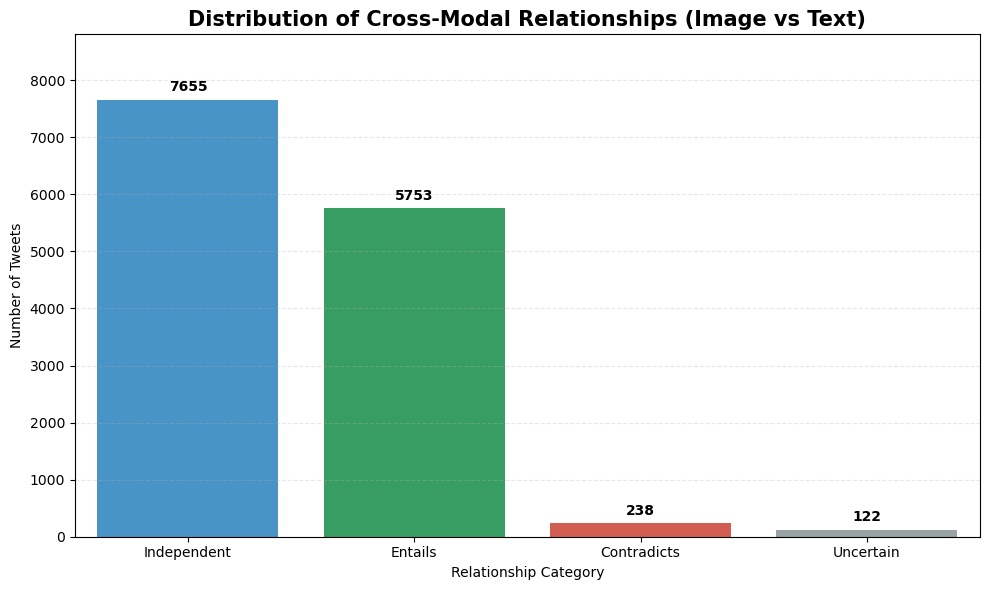


✅ RELIABILITY METRIC: 5753 images (41.8%) provide direct visual proof.
⚠️ NOISE METRIC: 7893 images are NOT direct evidence.


In [55]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Load the data (assuming df is already loaded)
# df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv")

# 2. Relationship Distribution Table
rel_counts = df['relationship_llm'].value_counts()
rel_percent = df['relationship_llm'].value_counts(normalize=True) * 100

rel_summary = pd.DataFrame({
    'Count': rel_counts,
    'Percentage (%)': rel_percent.round(2)
})

print("--- TASK 1: RELATIONSHIP LABEL ANALYSIS ---")
print(rel_summary)
print("-" * 45)

# 3. Visualization: The Entailment Landscape
plt.figure(figsize=(10, 6))
# Define colors: Green for Entails, Blue for Independent, Red for Contradicts/Uncertain
colors_map = {'Entails': '#27ae60', 'Independent': '#3498db', 'Contradicts': '#e74c3c', 'Uncertain': '#95a5a6'}
colors = [colors_map.get(x, '#bdc3c7') for x in rel_counts.index]

ax = sns.barplot(x=rel_counts.index, y=rel_counts.values, palette=colors, hue=rel_counts.index, legend=False)

# Add exact counts on top of bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points', 
                    fontweight='bold')

plt.title("Distribution of Cross-Modal Relationships (Image vs Text)", fontsize=15, fontweight='bold')
plt.xlabel("Relationship Category")
plt.ylabel("Number of Tweets")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.ylim(0, rel_counts.max() * 1.15) # Buffer for annotations
plt.tight_layout()

# --- SAVE THE CHART ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

rel_file_path = os.path.join(output_dir, "task1_relationship_distribution.png")
plt.savefig(rel_file_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Relationship Chart to: {rel_file_path}")

plt.show()

# 4. Impact Metric for Thesis
entails_count = rel_counts.get('Entails', 0)
print(f"\n✅ RELIABILITY METRIC: {entails_count} images ({rel_percent.get('Entails', 0):.1f}%) provide direct visual proof.")
print(f"⚠️ NOISE METRIC: {(rel_counts.get('Independent', 0) + rel_counts.get('Contradicts', 0))} images are NOT direct evidence.")

--- Text Category Agreement Analysis ---
Total Matches:    7184
Total Mismatches: 6584
Agreement Rate:   52.18%
----------------------------------------
✅ Chart saved successfully to: thesis_analysis_results\text_category_agreement_counts.png


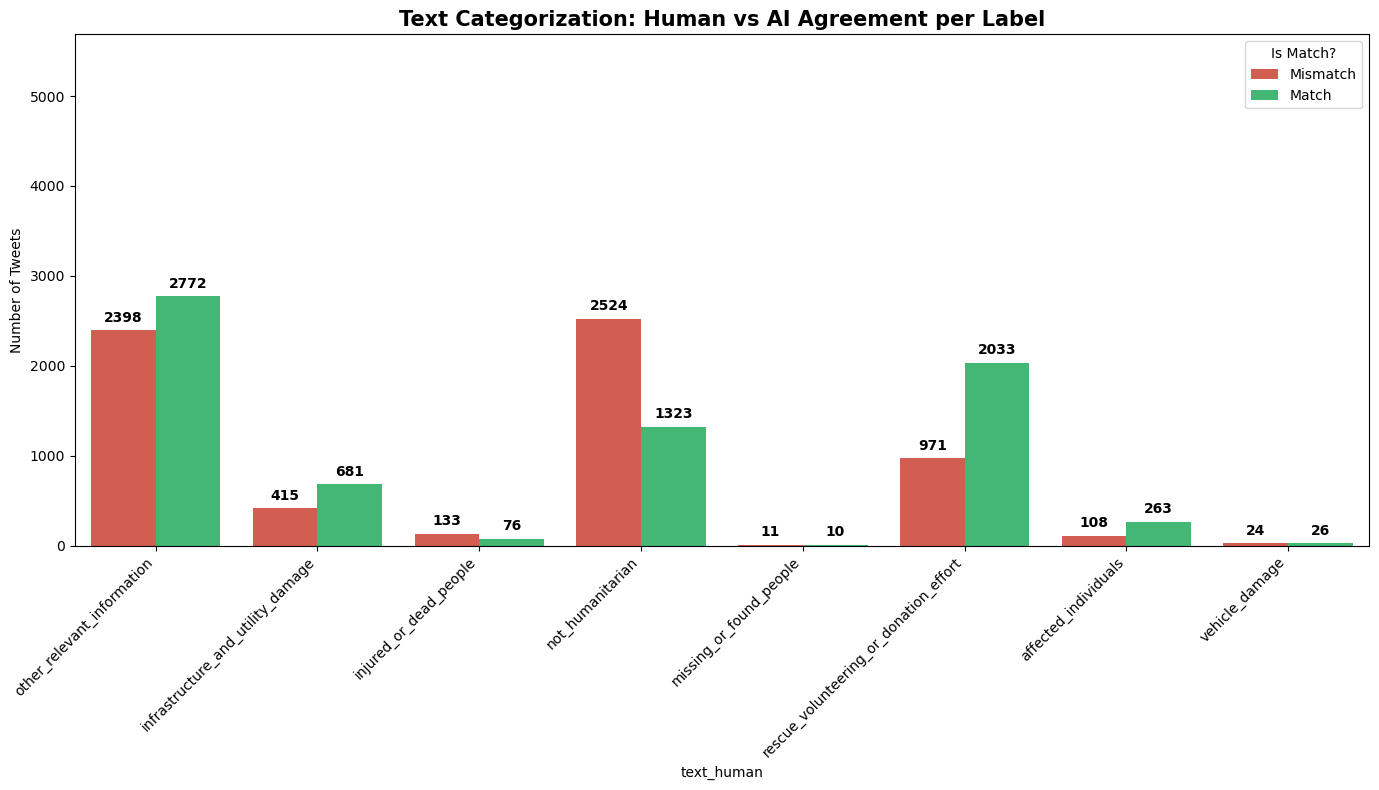

In [56]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Calculate matching rows
df['text_match'] = df['text_human'] == df['text_llm']
match_count = df['text_match'].sum()
mismatch_count = len(df) - match_count
accuracy = (match_count / len(df)) * 100

print(f"--- Text Category Agreement Analysis ---")
print(f"Total Matches:    {match_count}")
print(f"Total Mismatches: {mismatch_count}")
print(f"Agreement Rate:   {accuracy:.2f}%")
print("-" * 40)

# 2. Visualize the Top Matching vs Mismatching Labels
plt.figure(figsize=(14, 8))
ax = sns.countplot(
    data=df, 
    x='text_human', 
    hue='text_match', 
    palette={True: "#2ecc71", False: "#e74c3c"}
)

# --- ADD QUANTITIES ON TOP OF BARS ---
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
            (p.get_x() + p.get_width() / 2., p.get_height()), 
            ha='center', va='center', 
            xytext=(0, 9), 
            textcoords='offset points',
            fontsize=10,
            fontweight='bold')

plt.title("Text Categorization: Human vs AI Agreement per Label", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Match?", labels=["Mismatch", "Match"])
plt.ylabel("Number of Tweets")
plt.ylim(0, df['text_human'].value_counts().max() * 1.1) 
plt.tight_layout()

# --- ADDED SAVE LINE ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

save_path = os.path.join(output_dir, "text_category_agreement_counts.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"✅ Chart saved successfully to: {save_path}")

plt.show()

✅ Image chart saved successfully to: thesis_analysis_results\image_category_agreement_counts.png


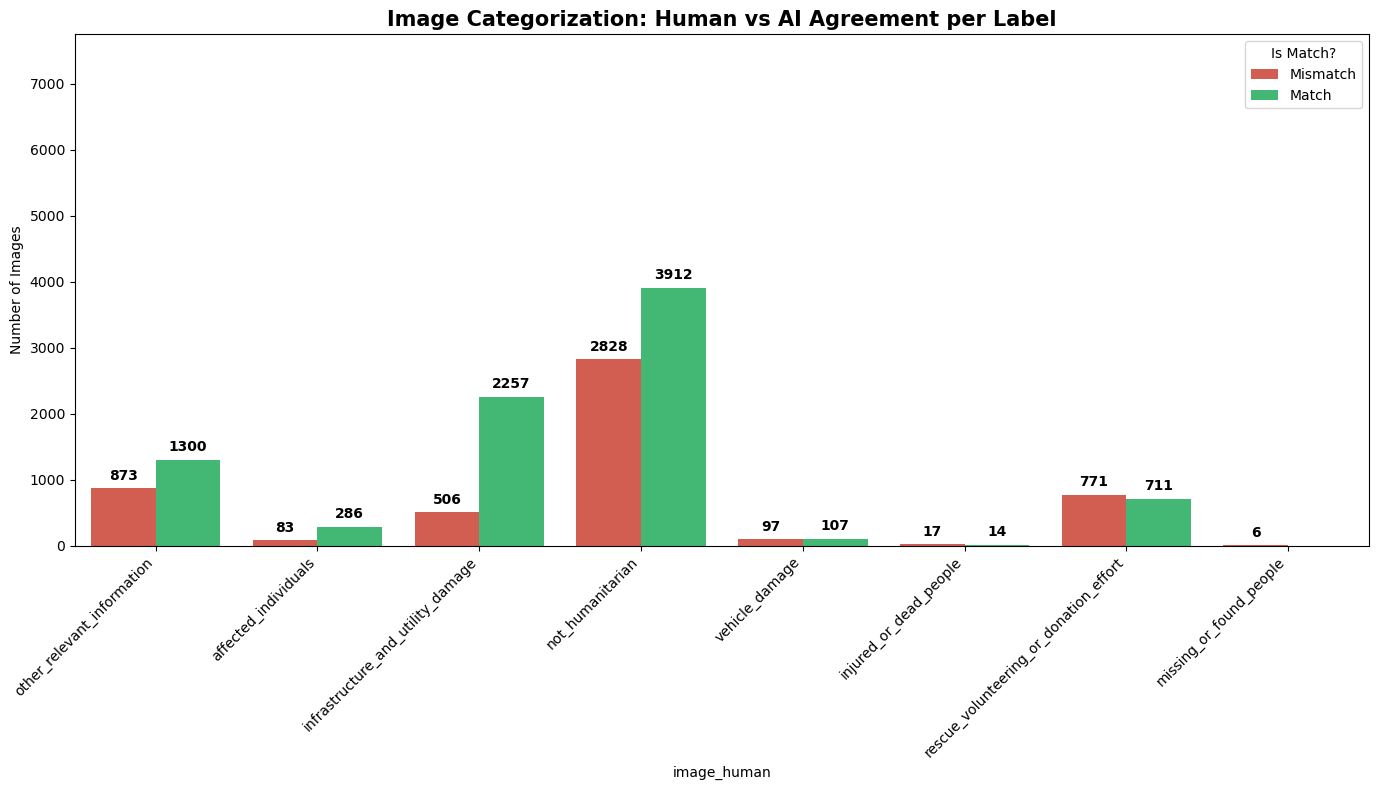

--- Image Category Results ---
Total Labeled Images: 13768
Overall Agreement:    62.37%


In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Filter for valid comparisons
comparison_df = df.dropna(subset=['image_human']).copy()
comparison_df['image_match'] = comparison_df['image_human'] == comparison_df['image_llm']

# 2. Visualize Image Category Agreement
plt.figure(figsize=(14, 8))
ax = sns.countplot(
    data=comparison_df, 
    x='image_human', 
    hue='image_match', 
    palette={True: "#2ecc71", False: "#e74c3c"}
)

# --- ADD QUANTITIES ON TOP OF BARS ---
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height), 
            ha='center', va='center', 
            xytext=(0, 9), 
            textcoords='offset points',
            fontsize=10,
            fontweight='bold')

plt.title("Image Categorization: Human vs AI Agreement per Label", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Match?", labels=["Mismatch", "Match"])
plt.ylabel("Number of Images")
plt.ylim(0, comparison_df['image_human'].value_counts().max() * 1.15)
plt.tight_layout()

# --- ADDED SAVE LINE ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

save_path_img = os.path.join(output_dir, "image_category_agreement_counts.png")
plt.savefig(save_path_img, dpi=300, bbox_inches='tight')
print(f"✅ Image chart saved successfully to: {save_path_img}")

plt.show()

# 3. Print Quick Summary Stats
match_count = comparison_df['image_match'].sum()
accuracy = (match_count / len(comparison_df)) * 100
print(f"--- Image Category Results ---")
print(f"Total Labeled Images: {len(comparison_df)}")
print(f"Overall Agreement:    {accuracy:.2f}%")

### Visualize each entry

 TWEET TEXT: #animals Colorado rescue groups to open doors for Harvey animals - FOX31 Denver https://t.co/lKGmpLafGj https://t.co/kfGpXUrYVH
----------------------------------------------------------------------------------------------------
 LLM REASONING: The image shows a man with a dog, likely indicating a rescue or emotional connection, which aligns with the tweet about rescue efforts for animals.
 BOX COORDS: [0, 0, 768, 1152] | EVIDENCE: emotional connection with a rescued animal
 QUALITY: Blur: 1.0/5 | Darkness: 1.0/5 | Occlusion: 1.0/5


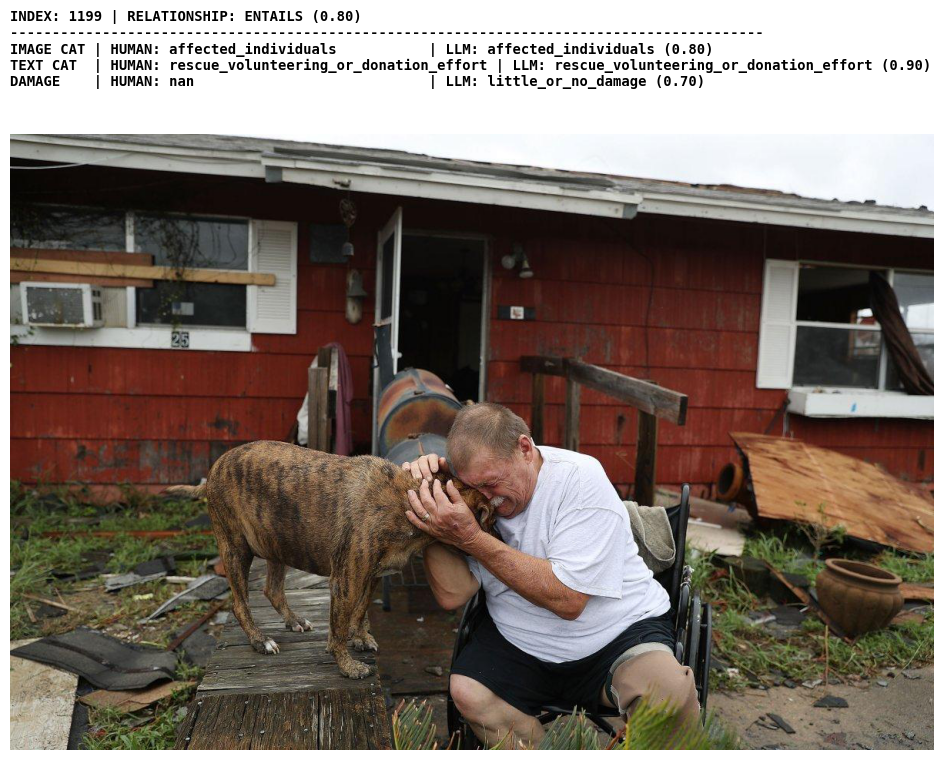

In [58]:
# 1. Load the dataset 
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", low_memory=False)
def display_benchmark_comparison_v3(df, index):
    try:
        row = df.loc[index]
        full_path = os.path.join(BASE_PATH, str(row['image_path']).replace('/', os.sep))
        
        # 1. Setup Figure
        img = Image.open(full_path)
        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.axis('off')
        
        # Helper to format confidence strings
        def fmt_conf(val):
            return f"({float(val):.2f})" if pd.notna(val) else "(N/A)"

        # 2. Construct the Detailed Title
        title_text = (
            f"INDEX: {index} | RELATIONSHIP: {row.get('relationship_llm', 'N/A').upper()} {fmt_conf(row.get('rel_conf'))}\n"
            f"{'-'*90}\n"
            f"IMAGE CAT | HUMAN: {row.get('image_human', 'N/A'):<30} | LLM: {row.get('image_llm', 'N/A')} {fmt_conf(row.get('image_llm_conf'))}\n"
            f"TEXT CAT  | HUMAN: {row.get('text_human', 'N/A'):<30} | LLM: {row.get('text_llm', 'N/A')} {fmt_conf(row.get('text_llm_conf'))}\n"
            f"DAMAGE    | HUMAN: {row.get('image_damage', 'N/A'):<30} | LLM: {row.get('image_damage_llm', 'N/A')} {fmt_conf(row.get('image_damage_llm_conf'))}"
        )
        
        plt.title(title_text, fontsize=10, fontweight='bold', family='monospace', loc='left', pad=35)
        
        # 3. Print Metadata & Reasoning
        print("="*100)
        print(f" TWEET TEXT: {row.get('tweet_text', 'N/A')}")
        print("-" * 100)
        print(f" LLM REASONING: {row.get('rel_reasoning', 'N/A')}")
        print(f" BOX COORDS: {row.get('box_2d', 'N/A')} | EVIDENCE: {row.get('evidence_type', 'N/A')}")
        print(f" QUALITY: Blur: {row.get('img_blur', '0')}/5 | Darkness: {row.get('img_darkness', '0')}/5 | Occlusion: {row.get('img_occlusion', '0')}/5")
        print("="*100)
        
        plt.show()
        
    except Exception as e:
        print(f"Error: {e}. Check if index {index} exists in your final_test_df.")

# Run the display on your test batch


display_benchmark_comparison_v3(df, 1199)

### saving all updated annotations

In [59]:
# 1. Load the processed dataset
# Make sure to use the file that contains your 13,768 processed rows
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv", low_memory=False)

# 2. Create the main output directory
output_root = "CrisisMMD_v2_Annotations"
if not os.path.exists(output_root):
    os.makedirs(output_root)

print(f"Starting export of {len(df)} rows into directory structure...")

# 3. Iterate through each disaster type (event_name)
# This mimics the original CrisisMMD folder structure
events = df['disaster_type'].unique()

for event in events:
    # Filter the dataframe for the specific disaster
    event_df = df[df['disaster_type'] == event]
    
    # Create the folder for this specific disaster
    event_folder = os.path.join(output_root, event)
    if not os.path.exists(event_folder):
        os.makedirs(event_folder)
    
    # Define the output path for the CSV
    # Usually named something like 'california_wildfires_final_data.csv'
    output_filename = f"{event}_updated_annotations.csv"
    output_path = os.path.join(event_folder, output_filename)
    
    # Save the file
    event_df.to_csv(output_path, index=False)
    print(f"✅ Exported {len(event_df)} rows to: {output_path}")

print("\n" + "="*50)
print(f"EXPORT COMPLETE: All files saved in '{output_root}'")
print("="*50)

Starting export of 13768 rows into directory structure...
✅ Exported 733 rows to: CrisisMMD_v2_Annotations\california_wildfires\california_wildfires_updated_annotations.csv
✅ Exported 3975 rows to: CrisisMMD_v2_Annotations\hurricane_harvey\hurricane_harvey_updated_annotations.csv
✅ Exported 4476 rows to: CrisisMMD_v2_Annotations\hurricane_irma\hurricane_irma_updated_annotations.csv
✅ Exported 4530 rows to: CrisisMMD_v2_Annotations\hurricane_maria\hurricane_maria_updated_annotations.csv
✅ Exported 54 rows to: CrisisMMD_v2_Annotations\iraq_iran_earthquake\iraq_iran_earthquake_updated_annotations.csv

EXPORT COMPLETE: All files saved in 'CrisisMMD_v2_Annotations'


### Phase 2 remaining dataset preprocessing 

In [60]:
# 1. Load the processed checkpoint
file_path = "CrisisMMD_Phase2_Master_Checkpoint.csv"
df = pd.read_csv(file_path, low_memory=False)
df.head()

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,...,text_llm_conf,image_llm,image_llm_conf,image_damage_llm,image_damage_llm_conf,box_2d,evidence_type,img_blur,img_darkness,img_occlusion
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,...,0.8,other_relevant_information,0.90,severe_damage,0.85,"[0, 0, 450, 800]",wildfire,1.0,1.0,0.0
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,...,0.8,affected_individuals,0.90,severe_damage,0.90,"[0, 0, 677, 1200]",destruction from wildfires,1.0,2.0,1.0
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,...,0.8,infrastructure_and_utility_damage,0.90,severe_damage,0.90,"[0, 0, 480, 640]",wildfire damage,1.0,2.0,1.0
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,...,0.9,other_relevant_information,0.85,dont_know_or_cant_judge,0.70,"[0, 0, 768, 1024]",press conference regarding emergency response,1.0,1.0,1.0
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,...,0.8,other_relevant_information,0.90,severe_damage,0.85,"[0, 0, 400, 600]",wildfire,1.0,2.0,1.0


In [61]:
df.head()

,tweet_id,image_id,text_info,text_info_conf,image_info,image_info_conf,text_human,text_human_conf,image_human,image_human_conf,...,text_llm_conf,image_llm,image_llm_conf,image_damage_llm,image_damage_llm_conf,box_2d,evidence_type,img_blur,img_darkness,img_occlusion
0,917791044158185473,917791044158185473_0,informative,1.0000,informative,0.6766,other_relevant_information,1.0000,other_relevant_information,0.6766,...,0.8,other_relevant_information,0.90,severe_damage,0.85,"[0, 0, 450, 800]",wildfire,1.0,1.0,0.0
1,917791130590183424,917791130590183424_0,informative,1.0000,informative,0.6667,infrastructure_and_utility_damage,1.0000,affected_individuals,0.6667,...,0.8,affected_individuals,0.90,severe_damage,0.90,"[0, 0, 677, 1200]",destruction from wildfires,1.0,2.0,1.0
2,917791291823591425,917791291823591425_0,informative,0.6813,informative,1.0000,other_relevant_information,0.6813,infrastructure_and_utility_damage,1.0000,...,0.8,infrastructure_and_utility_damage,0.90,severe_damage,0.90,"[0, 0, 480, 640]",wildfire damage,1.0,2.0,1.0
3,917791291823591425,917791291823591425_1,informative,0.6813,not_informative,1.0000,other_relevant_information,0.6813,not_humanitarian,1.0000,...,0.9,other_relevant_information,0.85,dont_know_or_cant_judge,0.70,"[0, 0, 768, 1024]",press conference regarding emergency response,1.0,1.0,1.0
4,917792092100988929,917792092100988929_0,informative,0.6727,informative,0.6612,other_relevant_information,0.6727,infrastructure_and_utility_damage,0.6612,...,0.8,other_relevant_information,0.90,severe_damage,0.85,"[0, 0, 400, 600]",wildfire,1.0,2.0,1.0


In [62]:
# Load the master checkpoint
MASTER_FILE = "CrisisMMD_Phase2_Master_Checkpoint.csv"
df_master = pd.read_csv(MASTER_FILE, low_memory=False)

# 1. Identify which rows are already done vs remaining
# We use 'relationship_llm' or 'image_damage_llm' as the indicator
df_processed = df_master[df_master['image_damage_llm'].notna()].copy()
df_remaining_raw = df_master[df_master['image_damage_llm'].isna()].copy()

# 2. DROP LLM columns from df_remaining to prevent duplicates during the batch process
# These are the columns we want to get fresh from the API
llm_cols_to_drop = [
    'relationship_llm', 'rel_reasoning', 'rel_conf', 
    'text_llm', 'text_llm_conf', 'image_llm', 'image_llm_conf', 
    'image_damage_llm', 'image_damage_llm_conf', 
    'box_2d', 'evidence_type', 'img_blur', 'img_darkness', 'img_occlusion'
]

# Only drop if they actually exist to avoid errors
df_remaining = df_remaining_raw.drop(columns=[c for c in llm_cols_to_drop if c in df_remaining_raw.columns])

# Save the already processed portion for merging later
df_processed.to_csv("processed_checkpoint.csv", index=False)

print(f"Status Update:")
print(f"- Processed rows (Saved): {len(df_processed)}")
print(f"- Remaining rows (Cleaned for processing): {len(df_remaining)}")

Status Update:
- Processed rows (Saved): 13768
- Remaining rows (Cleaned for processing): 4314


In [63]:


# --- 1. CONFIGURATION ---
REMAINING_FILE = "remaining_checkpoint.csv"
BATCH_SIZE = 100  # Small batch size as requested for frequent disk sync

# Check for existing progress to decide where to resume
if os.path.exists(REMAINING_FILE):
    # Load only the ID column to quickly count completed rows
    existing_progress = pd.read_csv(REMAINING_FILE, usecols=['tweet_id'])
    START_INDEX = len(existing_progress)
    print(f"🔄 Resuming from row {START_INDEX} due to previous shutdown/interruption...")
else:
    START_INDEX = 0
    print("🚀 Starting fresh processing for the remaining dataset...")

# --- 2. THE PROCESSING LOOP ---
total_remaining = len(df_remaining)

for i in range(START_INDEX, total_remaining, BATCH_SIZE):
    end_idx = min(i + BATCH_SIZE, total_remaining)
    print(f"📦 Working on batch: {i} to {end_idx} of {total_remaining}...")
    
    # 1. Slice the current chunk from the cleaned df_remaining
    current_chunk = df_remaining.iloc[i:end_idx].copy()
    
    try:
        # 2. Process the chunk using your existing LLM function
        processed_chunk = process_batch(current_chunk)
        
        # 3. IMMEDIATE DISK SYNC (Mode 'a' for Append)
        # This protects data if the PC shuts down in the next 5 minutes
        file_exists = os.path.isfile(REMAINING_FILE)
        processed_chunk.to_csv(
            REMAINING_FILE, 
            mode='a', 
            index=False, 
            header=not file_exists
        )
        
        print(f"✅ Saved up to row {end_idx}. Physical file updated.")
        
        # 4. Short pause to let the system rest
        time.sleep(2)
        
    except Exception as e:
        print(f"❌ Error encountered at row {i}: {e}")
        print("Progress is safe on disk. Restart the cell to resume.")
        break

print("\n" + "="*40)
print(f"🏁 DONE: Final results saved in {REMAINING_FILE}")
print("="*40)

🔄 Resuming from row 4314 due to previous shutdown/interruption...

🏁 DONE: Final results saved in remaining_checkpoint.csv


In [64]:

# # --- UPDATED CHECK CODE ---
# REMAINING_FILE = "remaining_checkpoint.csv"

# if os.path.exists(REMAINING_FILE):
#     # Load the data that has been physically saved to disk
#     df_disk_check = pd.read_csv(REMAINING_FILE)
    
#     total_saved = len(df_disk_check)
#     print(f"✅ Successfully captured {total_saved} rows on disk before interruption.")
#     print("-" * 30)
    
#     # Columns we want to verify
#     check_cols = ['tweet_text', 'relationship_llm', 'image_damage_llm', 'box_2d']
#     available_cols = [c for c in check_cols if c in df_disk_check.columns]
    
#     print("Preview of the last 5 rows saved to your PC:")
#     display(df_disk_check[available_cols].tail(5))
    
#     # Check for LLM errors or empty labels in the saved file
#     if 'image_damage_llm' in df_disk_check.columns:
#         null_count = df_disk_check['image_damage_llm'].isna().sum()
#         if null_count > 0:
#             print(f"⚠️ Warning: {null_count} rows in the file are missing labels.")
            
#     if 'error' in df_disk_check.columns:
#         error_count = df_disk_check['error'].notna().sum()
#         print(f"⚠️ Warning: {error_count} rows contain explicit API errors.")
        
# else:
#     print(f"❌ The file '{REMAINING_FILE}' does not exist yet. No data has been saved to disk.")

In [65]:
# Load both processed parts
df_part1 = pd.read_csv("processed_checkpoint.csv")
df_part2 = pd.read_csv("remaining_checkpoint.csv")

# Merge them vertically
df_final_plus_plus = pd.concat([df_part1, df_part2], ignore_index=True)

# --- SAFETY CHECK: Remove Duplicates ---
# In case a batch was processed twice during a PC restart
initial_count = len(df_final_plus_plus)
df_final_plus_plus = df_final_plus_plus.drop_duplicates(subset=['tweet_id', 'image_id'])
final_count = len(df_final_plus_plus)

if initial_count != final_count:
    print(f"⚠️ Removed {initial_count - final_count} duplicate rows found during merging.")

# --- FINAL VALIDATION ---
print(f"Final Count: {final_count}")
if final_count == 18082:
    print("✅ Success: The dataset is complete (18,082/18,082).")
else:
    print(f"ℹ️ Note: Dataset contains {final_count} rows.")

# Save the master final version
FINAL_OUTPUT_PATH = "CrisisMMD_PlusPlus_Final_Labels.csv"
df_final_plus_plus.to_csv(FINAL_OUTPUT_PATH, index=False)

print(f"Merge Complete! Master file saved as: {FINAL_OUTPUT_PATH}")

Final Count: 18082
✅ Success: The dataset is complete (18,082/18,082).
Merge Complete! Master file saved as: CrisisMMD_PlusPlus_Final_Labels.csv


In [66]:
# OUTPUT_DIR = "annotations++"
# if not os.path.exists(OUTPUT_DIR):
#     os.makedirs(OUTPUT_DIR)

# # Get unique disaster events
# events = df_final_plus_plus['disaster_type'].unique()

# for event in events:
#     # Filter data for this specific disaster
#     event_df = df_final_plus_plus[df_final_plus_plus['disaster_type'] == event]
    
#     # Create the sub-folder
#     event_path = os.path.join(OUTPUT_DIR, str(event))
#     if not os.path.exists(event_path):
#         os.makedirs(event_path)
    
#     # Save the disaster-specific CSV
#     csv_name = f"{event}_final_annotations.csv"
#     event_df.to_csv(os.path.join(event_path, csv_name), index=False)
    
#     print(f"Exported: {event} ({len(event_df)} images)")

# print("\n" + "="*40)
# print(f"SUCCESS: All annotations saved in original folder structure within '{OUTPUT_DIR}'")
# print("="*40)

Exported: california_wildfires (1589 images)
Exported: hurricane_harvey (4434 images)
Exported: hurricane_irma (4504 images)
Exported: hurricane_maria (4556 images)
Exported: iraq_iran_earthquake (597 images)
Exported: mexico_earthquake (1380 images)
Exported: srilanka_floods (1022 images)

SUCCESS: All annotations saved in original folder structure within 'annotations++'


In [67]:

print("Master Task labels without LLM")
print(master_task_df.columns.tolist())


print("df_remaining columns")
print(df_remaining.columns.tolist())

Master Task labels without LLM
['tweet_id', 'image_id', 'text_info', 'text_info_conf', 'image_info', 'image_info_conf', 'text_human', 'text_human_conf', 'image_human', 'image_human_conf', 'image_damage', 'image_damage_conf', 'tweet_text', 'image_url', 'image_path', 'disaster_type', 'image_hash', 'perceptual_hash', 'has_phash_duplicate', 'split']
df_remaining columns
['tweet_id', 'image_id', 'text_info', 'text_info_conf', 'image_info', 'image_info_conf', 'text_human', 'text_human_conf', 'image_human', 'image_human_conf', 'image_damage', 'image_damage_conf', 'tweet_text', 'image_url', 'image_path', 'disaster_type', 'image_hash', 'perceptual_hash', 'has_phash_duplicate', 'split']


In [68]:
# 1. Load the processed checkpoint
file_path = "CrisisMMD_PlusPlus_Final_Labels.csv"
df = pd.read_csv(file_path, low_memory=False)

# 2. Define the extra labels found during AI processing
# These are the "Open-Set" labels the model generated that we want to merge
extra_labels = ["not_humanitarian", "other_relevant_information"]
target_label = "dont_know_or_cant_judge"

# 3. Perform the replacement in the AI-generated column
df['image_damage_llm'] = df['image_damage_llm'].replace(extra_labels, target_label)

# 4. Verification: Print unique labels to ensure exactly 4 remain
unique_labels = df['image_damage_llm'].dropna().unique()
print(f"--- Label Cleanup Complete ---")
print(f"Total processed rows: {len(df[df['image_damage_llm'].notna()])}")
print(f"Unique Labels in 'image_damage_llm':\n{unique_labels}")

# 5. Save the cleaned version for the next steps
df.to_csv("CrisisMMD_Phase2_Final_Clean_final.csv", index=False)
print(f"\n✅ Cleaned file saved as: CrisisMMD_Phase2_Final_Clean.csv")

--- Label Cleanup Complete ---
Total processed rows: 18082
Unique Labels in 'image_damage_llm':
['severe_damage' 'dont_know_or_cant_judge' 'little_or_no_damage'
 'mild_damage' 'infrastructure_and_utility_damage']

✅ Cleaned file saved as: CrisisMMD_Phase2_Final_Clean.csv


In [69]:
# 1. Define file paths
INPUT_FILE = "CrisisMMD_Phase2_Final_Clean_final.csv"
OUTPUT_FILE = "CrisisMMD_Phase2_Final_Clean_final.csv"

# 2. Load the data
if os.path.exists(INPUT_FILE):
    df = pd.read_csv(INPUT_FILE, low_memory=False)
    initial_count = len(df)
    
    # 3. Create the new Master_df by dropping NaN entries
    # We subset on the LLM columns to ensure our 'Y' labels are valid for training
    master_df_clean = df.dropna(subset=['relationship_llm', 'image_damage_llm']).copy()
    
    final_count = len(master_df_clean)
    dropped_count = initial_count - final_count

    # 4. Final Audit
    print("--- Cleaning Report ---")
    print(f"Original entries: {initial_count}")
    print(f"Dropped (NaN):    {dropped_count}")
    print(f"Final entries:    {final_count}")
    
    # 5. Save the new Master_df
    master_df_clean.to_csv(OUTPUT_FILE, index=False)
    print(f"\n✅ Success! New Master_df saved to: {OUTPUT_FILE}")
    
    # 6. Quick check of remaining data
    print("\n--- Remaining Disaster Type Distribution ---")
    print(master_df_clean['disaster_type'].value_counts())

else:
    print(f"❌ Error: {INPUT_FILE} not found.")

--- Cleaning Report ---
Original entries: 18082
Dropped (NaN):    0
Final entries:    18082

✅ Success! New Master_df saved to: CrisisMMD_Phase2_Final_Clean_final.csv

--- Remaining Disaster Type Distribution ---
disaster_type
hurricane_maria         4556
hurricane_irma          4504
hurricane_harvey        4434
california_wildfires    1589
mexico_earthquake       1380
srilanka_floods         1022
iraq_iran_earthquake     597
Name: count, dtype: int64


In [73]:
import pandas as pd
import os

# 1. Re-read all original TSV files to get the raw 'image_damage' (with NaNs)
all_tsvs = []
annotations_dir = os.path.join(str(BASE_PATH), 'annotations')

for filename in os.listdir(annotations_dir):
    if filename.endswith('.tsv') and not filename.startswith('._'):
        temp_df = pd.read_csv(os.path.join(annotations_dir, filename), sep='\t')
        all_tsvs.append(temp_df)

# This dataframe contains the original human NaNs
original_raw_df = pd.concat(all_tsvs, ignore_index=True)

# 2. Load your processed AI data
# (Ensure this is the file where you already cleaned the LLM labels)
ai_processed_df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_final.csv", low_memory=False)

# 3. Create the comparison dataset
# We take the AI results and replace the human 'image_damage' column 
# with the one from the original_raw_df based on 'image_id'
final_clean_with_nans = pd.merge(
    original_raw_df[['image_id', 'image_damage']], 
    ai_processed_df.drop(columns=['image_damage']), 
    on='image_id', 
    how='right'
)

# 4. Save and Verify
final_clean_with_nans.to_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv", index=False)

print(f"--- Data Replacement Complete ---")
print(f"Total Rows: {len(final_clean_with_nans)}")
print(f"Original Human NaNs restored: {final_clean_with_nans['image_damage'].isna().sum()}")
print(f"File Saved: CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv")

--- Data Replacement Complete ---
Total Rows: 18082
Original Human NaNs restored: 14455
File Saved: CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv


✅ Saved Bar Chart to: thesis_analysis_results\human_vs_ai_distribution_final.png


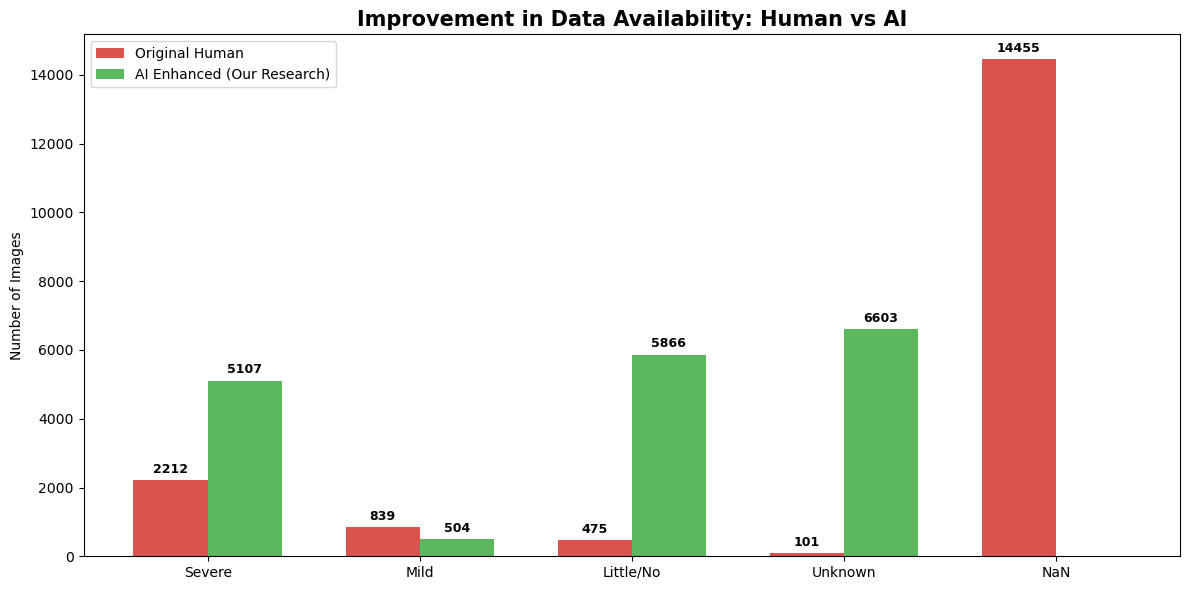

✅ Saved Pie Chart to: thesis_analysis_results\recovery_success_pie_final.png


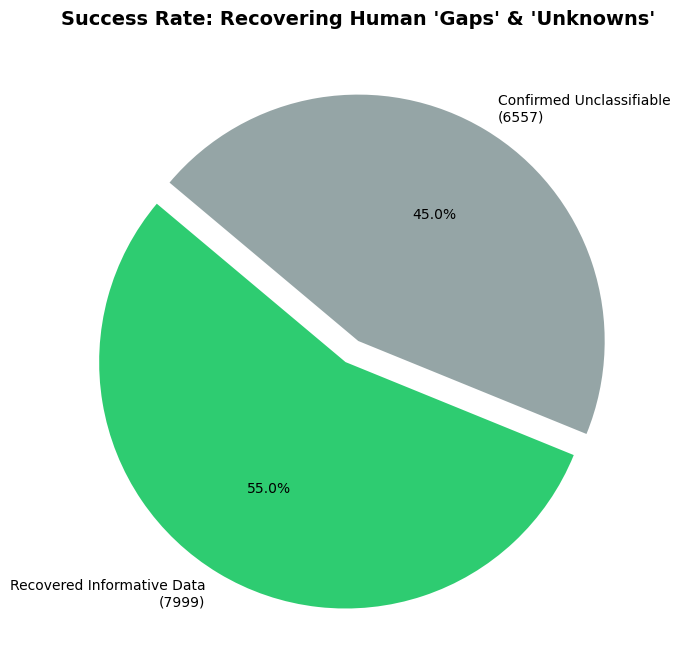

In [81]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os

# Create a directory for your thesis figures if it doesn't exist
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# 1. Load the data
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv", low_memory=False)

# 2. Preparation
informative_labels = ['severe_damage', 'mild_damage', 'little_or_no_damage']
uninformative_val = 'dont_know_or_cant_judge'
df['human_status'] = df['image_damage'].fillna('Pure NaN (Skipped)')

# --- [TABLE DATA GENERATION REMAINS THE SAME] ---
# ... (your existing table print logic) ...

# --- VISUALIZATION 1: SIDE-BY-SIDE DISTRIBUTION ---
plot_data_human = df['image_damage'].fillna('Missing (NaN)').value_counts().reindex(
    ['severe_damage', 'mild_damage', 'little_or_no_damage', 'dont_know_or_cant_judge', 'Missing (NaN)']
)
plot_data_ai = df['image_damage_llm'].value_counts().reindex(
    ['severe_damage', 'mild_damage', 'little_or_no_damage', 'dont_know_or_cant_judge']
)

labels = ['Severe', 'Mild', 'Little/No', 'Unknown', 'NaN']
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, plot_data_human.values, width, label='Original Human', color='#d9534f')
ai_vals = list(plot_data_ai.values) + [0]
rects2 = ax.bar(x + width/2, ai_vals, width, label='AI Enhanced (Our Research)', color='#5cb85c')

ax.set_ylabel('Number of Images')
ax.set_title('Improvement in Data Availability: Human vs AI', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        if height > 0:
            ax.annotate(f'{int(height)}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(rects1)
autolabel(rects2)
plt.tight_layout()

# SAVE BAR CHART
bar_chart_path = os.path.join(output_dir, "human_vs_ai_distribution_final.png")
plt.savefig(bar_chart_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Bar Chart to: {bar_chart_path}")
plt.show()

# --- VISUALIZATION 2: THE "RECOVERY" PIE CHART ---
total_uninformative = (df['image_damage'].isna() | (df['image_damage'] == uninformative_val)).sum()
recovered_count = (df[df['image_damage'].isna() | (df['image_damage'] == uninformative_val)]['image_damage_llm'].isin(informative_labels)).sum()
still_unknown = total_uninformative - recovered_count

plt.figure(figsize=(8, 8))
plt.pie([recovered_count, still_unknown], 
        labels=[f'Recovered Informative Data\n({recovered_count})', f'Confirmed Unclassifiable\n({still_unknown})'],
        autopct='%1.1f%%', colors=['#2ecc71', '#95a5a6'], startangle=140, explode=(0.1, 0))
plt.title("Success Rate: Recovering Human 'Gaps' & 'Unknowns'", fontsize=14, fontweight='bold')

# SAVE PIE CHART
pie_chart_path = os.path.join(output_dir, "recovery_success_pie_final.png")
plt.savefig(pie_chart_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Pie Chart to: {pie_chart_path}")
plt.show()

✅ Saved Exploration Chart to: thesis_analysis_results\human_blind_spot_exploration_final.png


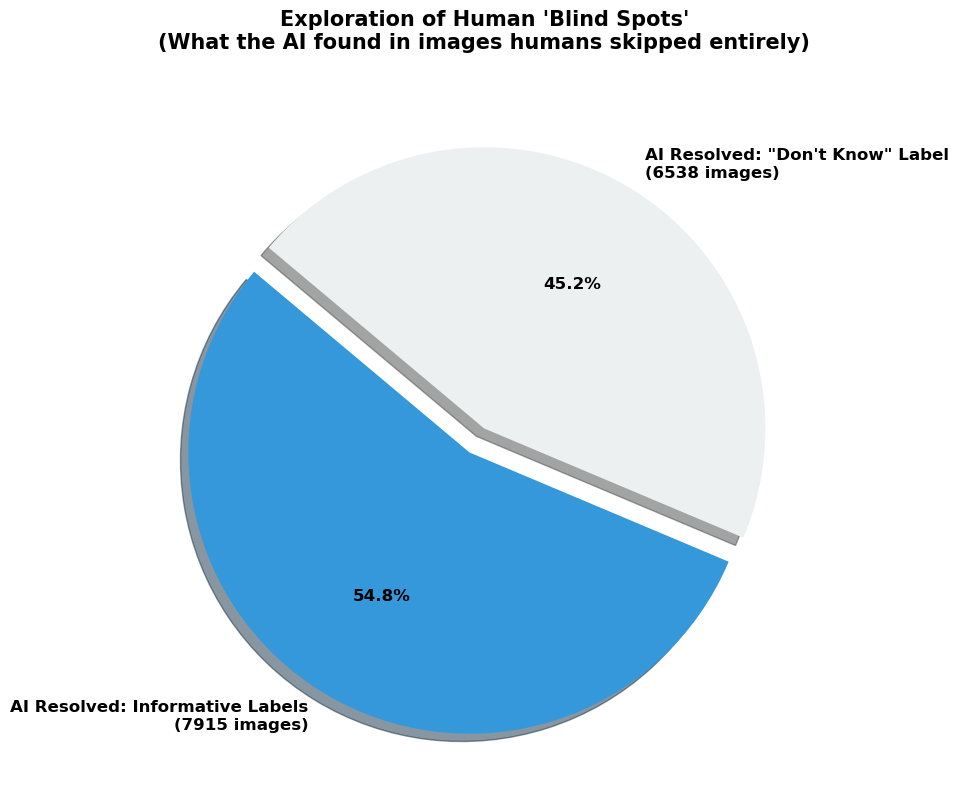

🚀 RESEARCH ANALYSIS: EXPLORING THE UNEXPLORED
Total images ignored by Human Annotators: 14455
AI Exploration Coverage:                   100%
Informative Data recovered from the void:  7915 images


In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Load the dataset 
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv", low_memory=False)

# 2. Filter ONLY for images that humans skipped (Pure NaN)
human_skipped_df = df[df['image_damage'].isna()].copy()

# 3. Categorize AI actions
informative_labels = ['severe_damage', 'mild_damage', 'little_or_no_damage']
rescued_informative = human_skipped_df['image_damage_llm'].isin(informative_labels).sum()
acknowledged_dont_know = (human_skipped_df['image_damage_llm'] == 'dont_know_or_cant_judge').sum()

# 4. Visualization
labels = [
    f'AI Resolved: Informative Labels\n({rescued_informative} images)', 
    f'AI Resolved: "Don\'t Know" Label\n({acknowledged_dont_know} images)'
]
sizes = [rescued_informative, acknowledged_dont_know]
colors = ['#3498db', '#ecf0f1'] 

plt.figure(figsize=(10, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, 
        colors=colors, explode=(0.1, 0), shadow=True, textprops={'fontsize': 12, 'weight': 'bold'})

plt.title("Exploration of Human 'Blind Spots'\n(What the AI found in images humans skipped entirely)", 
          fontsize=15, fontweight='bold', pad=20)

plt.tight_layout()

# --- SAVE THE CHART ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

file_path = os.path.join(output_dir, "human_blind_spot_exploration_final.png")
plt.savefig(file_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Exploration Chart to: {file_path}")

plt.show()

# 5. Impact Metrics
print("="*60)
print("🚀 RESEARCH ANALYSIS: EXPLORING THE UNEXPLORED")
print("="*60)
print(f"Total images ignored by Human Annotators: {len(human_skipped_df)}")
print(f"AI Exploration Coverage:                   100%")
print(f"Informative Data recovered from the void:  {rescued_informative} images")
print("="*60)

--- TASK 1: RELATIONSHIP LABEL ANALYSIS ---
                  Count  Percentage (%)
relationship_llm                       
Independent        9730           53.81
Entails            7848           43.40
Contradicts         325            1.80
Uncertain           179            0.99
---------------------------------------------
✅ Saved Relationship Chart to: thesis_analysis_results\task1_relationship_distribution_final.png


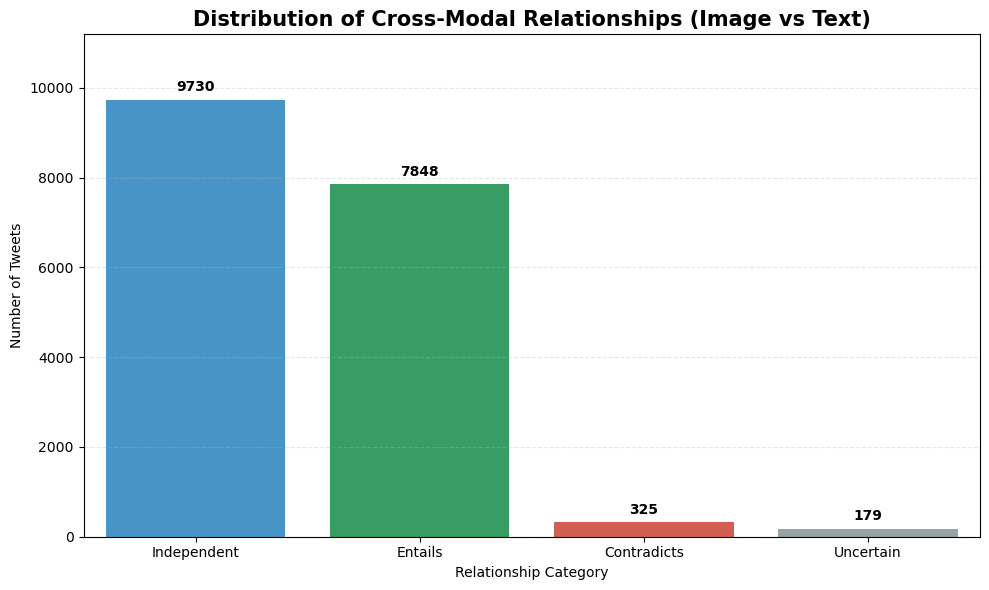


✅ RELIABILITY METRIC: 7848 images (43.4%) provide direct visual proof.
⚠️ NOISE METRIC: 10055 images are NOT direct evidence.


In [85]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Load the data (assuming df is already loaded)
# df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs.csv")

# 2. Relationship Distribution Table
rel_counts = df['relationship_llm'].value_counts()
rel_percent = df['relationship_llm'].value_counts(normalize=True) * 100

rel_summary = pd.DataFrame({
    'Count': rel_counts,
    'Percentage (%)': rel_percent.round(2)
})

print("--- TASK 1: RELATIONSHIP LABEL ANALYSIS ---")
print(rel_summary)
print("-" * 45)

# 3. Visualization: The Entailment Landscape
plt.figure(figsize=(10, 6))
# Define colors: Green for Entails, Blue for Independent, Red for Contradicts/Uncertain
colors_map = {'Entails': '#27ae60', 'Independent': '#3498db', 'Contradicts': '#e74c3c', 'Uncertain': '#95a5a6'}
colors = [colors_map.get(x, '#bdc3c7') for x in rel_counts.index]

ax = sns.barplot(x=rel_counts.index, y=rel_counts.values, palette=colors, hue=rel_counts.index, legend=False)

# Add exact counts on top of bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='center', xytext=(0, 9), textcoords='offset points', 
                    fontweight='bold')

plt.title("Distribution of Cross-Modal Relationships (Image vs Text)", fontsize=15, fontweight='bold')
plt.xlabel("Relationship Category")
plt.ylabel("Number of Tweets")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.ylim(0, rel_counts.max() * 1.15) # Buffer for annotations
plt.tight_layout()

# --- SAVE THE CHART ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

rel_file_path = os.path.join(output_dir, "task1_relationship_distribution_final.png")
plt.savefig(rel_file_path, dpi=300, bbox_inches='tight')
print(f"✅ Saved Relationship Chart to: {rel_file_path}")

plt.show()

# 4. Impact Metric for Thesis
entails_count = rel_counts.get('Entails', 0)
print(f"\n✅ RELIABILITY METRIC: {entails_count} images ({rel_percent.get('Entails', 0):.1f}%) provide direct visual proof.")
print(f"⚠️ NOISE METRIC: {(rel_counts.get('Independent', 0) + rel_counts.get('Contradicts', 0))} images are NOT direct evidence.")

--- Text Category Agreement Analysis ---
Total Matches:    9336
Total Mismatches: 8746
Agreement Rate:   51.63%
----------------------------------------
✅ Chart saved successfully to: thesis_analysis_results\text_category_agreement_counts_final.png


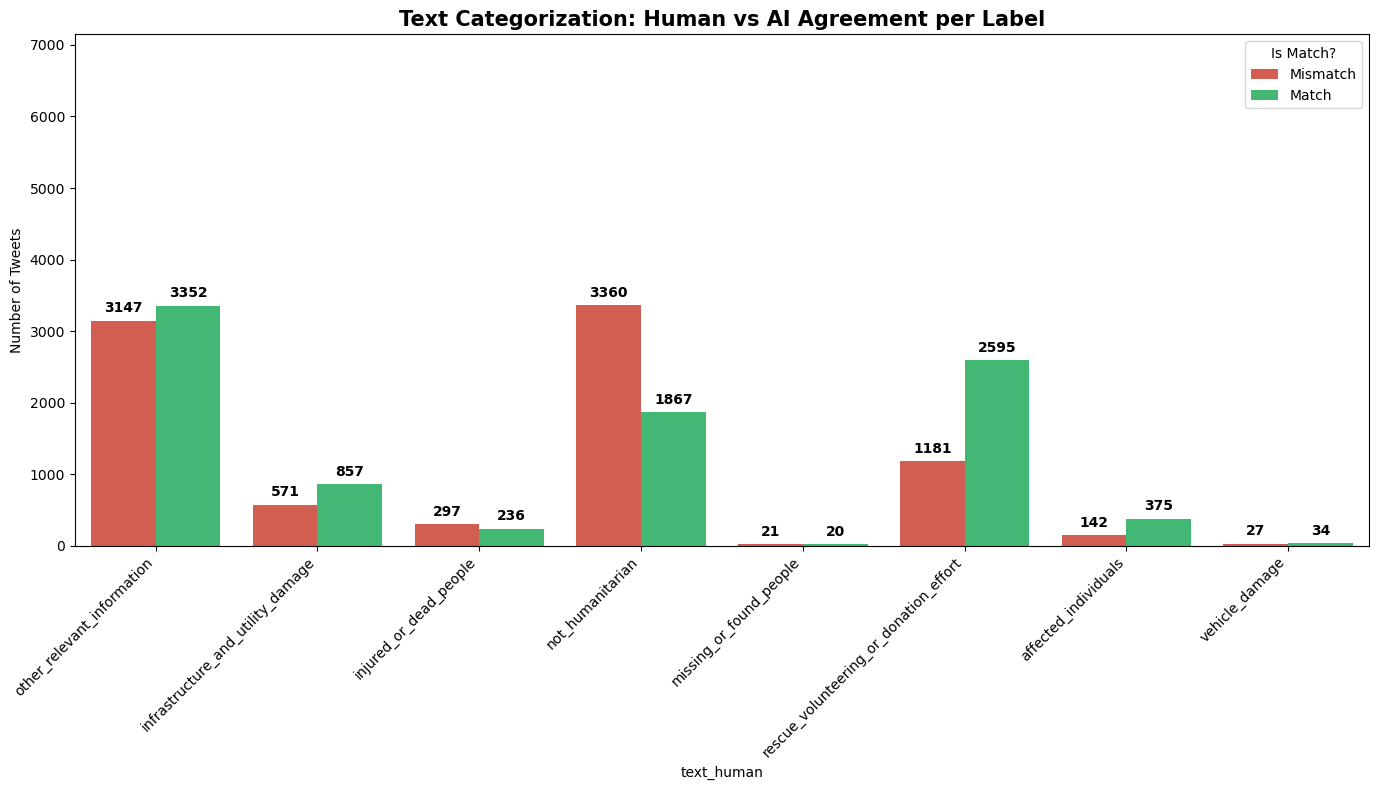

In [83]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Calculate matching rows
df['text_match'] = df['text_human'] == df['text_llm']
match_count = df['text_match'].sum()
mismatch_count = len(df) - match_count
accuracy = (match_count / len(df)) * 100

print(f"--- Text Category Agreement Analysis ---")
print(f"Total Matches:    {match_count}")
print(f"Total Mismatches: {mismatch_count}")
print(f"Agreement Rate:   {accuracy:.2f}%")
print("-" * 40)

# 2. Visualize the Top Matching vs Mismatching Labels
plt.figure(figsize=(14, 8))
ax = sns.countplot(
    data=df, 
    x='text_human', 
    hue='text_match', 
    palette={True: "#2ecc71", False: "#e74c3c"}
)

# --- ADD QUANTITIES ON TOP OF BARS ---
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{int(p.get_height())}', 
            (p.get_x() + p.get_width() / 2., p.get_height()), 
            ha='center', va='center', 
            xytext=(0, 9), 
            textcoords='offset points',
            fontsize=10,
            fontweight='bold')

plt.title("Text Categorization: Human vs AI Agreement per Label", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Match?", labels=["Mismatch", "Match"])
plt.ylabel("Number of Tweets")
plt.ylim(0, df['text_human'].value_counts().max() * 1.1) 
plt.tight_layout()

# --- ADDED SAVE LINE ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

save_path = os.path.join(output_dir, "text_category_agreement_counts_final.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"✅ Chart saved successfully to: {save_path}")

plt.show()

✅ Image chart saved successfully to: thesis_analysis_results\image_category_agreement_counts_final.png


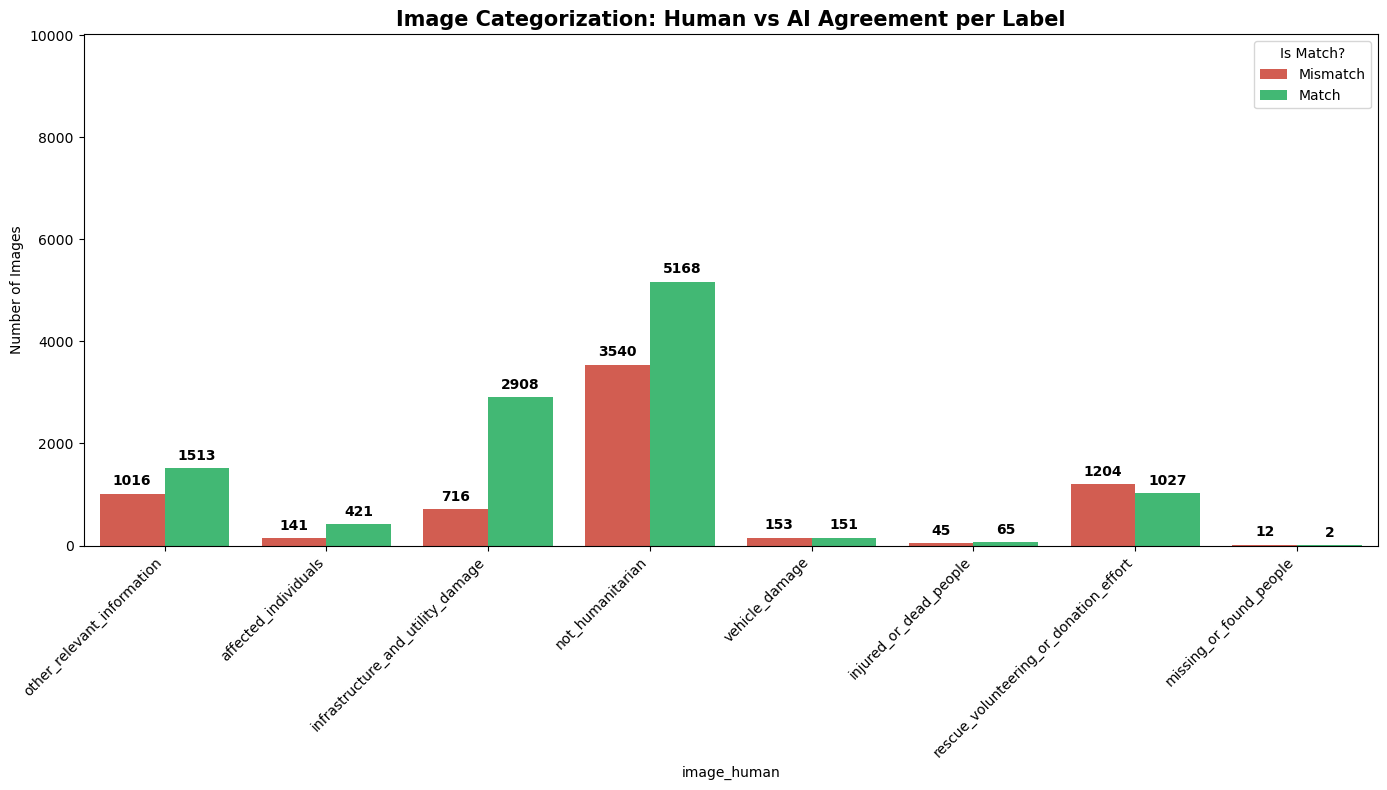

--- Image Category Results ---
Total Labeled Images: 18082
Overall Agreement:    62.24%


In [84]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# 1. Filter for valid comparisons
comparison_df = df.dropna(subset=['image_human']).copy()
comparison_df['image_match'] = comparison_df['image_human'] == comparison_df['image_llm']

# 2. Visualize Image Category Agreement
plt.figure(figsize=(14, 8))
ax = sns.countplot(
    data=comparison_df, 
    x='image_human', 
    hue='image_match', 
    palette={True: "#2ecc71", False: "#e74c3c"}
)

# --- ADD QUANTITIES ON TOP OF BARS ---
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height), 
            ha='center', va='center', 
            xytext=(0, 9), 
            textcoords='offset points',
            fontsize=10,
            fontweight='bold')

plt.title("Image Categorization: Human vs AI Agreement per Label", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Match?", labels=["Mismatch", "Match"])
plt.ylabel("Number of Images")
plt.ylim(0, comparison_df['image_human'].value_counts().max() * 1.15)
plt.tight_layout()

# --- ADDED SAVE LINE ---
output_dir = "thesis_analysis_results"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

save_path_img = os.path.join(output_dir, "image_category_agreement_counts_final.png")
plt.savefig(save_path_img, dpi=300, bbox_inches='tight')
print(f"✅ Image chart saved successfully to: {save_path_img}")

plt.show()

# 3. Print Quick Summary Stats
match_count = comparison_df['image_match'].sum()
accuracy = (match_count / len(comparison_df)) * 100
print(f"--- Image Category Results ---")
print(f"Total Labeled Images: {len(comparison_df)}")
print(f"Overall Agreement:    {accuracy:.2f}%")

 TWEET TEXT: 5 Ways You Can Help Mexico After the Deadly Earthquake https://t.co/u40scdC0hr #entrepreneur #business https://t.co/dxbJbFYLjH
----------------------------------------------------------------------------------------------------
 LLM REASONING: The image shows rescue efforts in the aftermath of an earthquake, which directly supports the tweet's call for help after a deadly earthquake.
 BOX COORDS: [0, 0, 768, 1152] | EVIDENCE: rescue efforts amidst structural collapse
 QUALITY: Blur: 1.0/5 | Darkness: 1.0/5 | Occlusion: 1.0/5


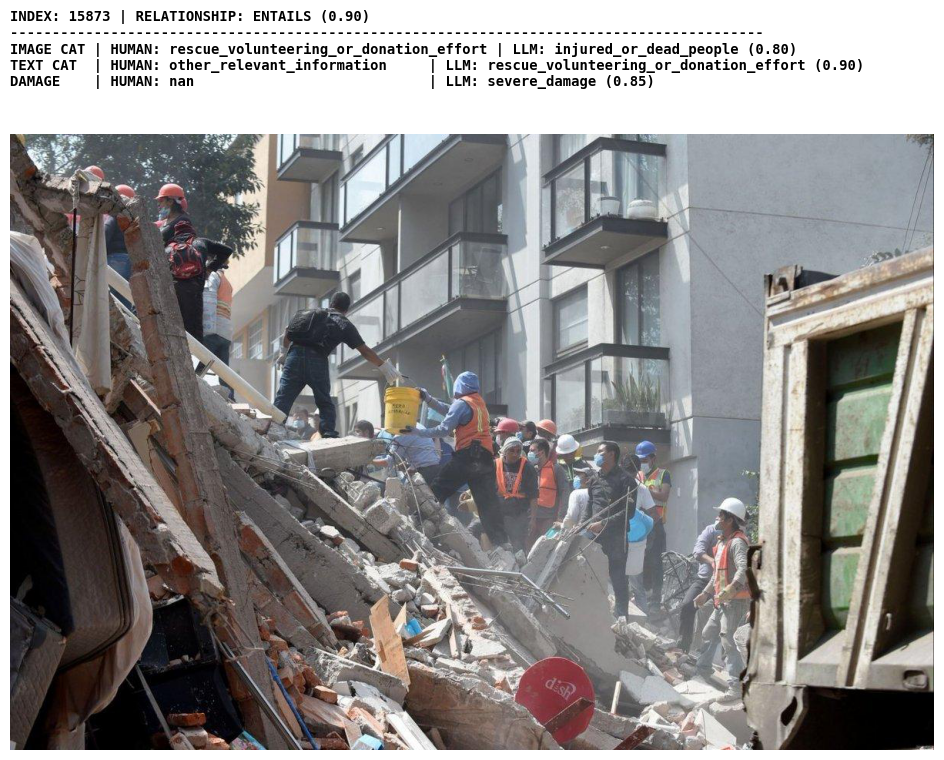

In [56]:
# 1. Load the dataset 
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv", low_memory=False)
def display_benchmark_comparison_v3(df, index):
    try:
        row = df.loc[index]
        full_path = os.path.join(BASE_PATH, str(row['image_path']).replace('/', os.sep))
        
        # 1. Setup Figure
        img = Image.open(full_path)
        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.axis('off')
        
        # Helper to format confidence strings
        def fmt_conf(val):
            return f"({float(val):.2f})" if pd.notna(val) else "(N/A)"

        # 2. Construct the Detailed Title
        title_text = (
            f"INDEX: {index} | RELATIONSHIP: {row.get('relationship_llm', 'N/A').upper()} {fmt_conf(row.get('rel_conf'))}\n"
            f"{'-'*90}\n"
            f"IMAGE CAT | HUMAN: {row.get('image_human', 'N/A'):<30} | LLM: {row.get('image_llm', 'N/A')} {fmt_conf(row.get('image_llm_conf'))}\n"
            f"TEXT CAT  | HUMAN: {row.get('text_human', 'N/A'):<30} | LLM: {row.get('text_llm', 'N/A')} {fmt_conf(row.get('text_llm_conf'))}\n"
            f"DAMAGE    | HUMAN: {row.get('image_damage', 'N/A'):<30} | LLM: {row.get('image_damage_llm', 'N/A')} {fmt_conf(row.get('image_damage_llm_conf'))}"
        )
        
        plt.title(title_text, fontsize=10, fontweight='bold', family='monospace', loc='left', pad=35)
        
        # 3. Print Metadata & Reasoning
        print("="*100)
        print(f" TWEET TEXT: {row.get('tweet_text', 'N/A')}")
        print("-" * 100)
        print(f" LLM REASONING: {row.get('rel_reasoning', 'N/A')}")
        print(f" BOX COORDS: {row.get('box_2d', 'N/A')} | EVIDENCE: {row.get('evidence_type', 'N/A')}")
        print(f" QUALITY: Blur: {row.get('img_blur', '0')}/5 | Darkness: {row.get('img_darkness', '0')}/5 | Occlusion: {row.get('img_occlusion', '0')}/5")
        print("="*100)
        
        plt.show()
        
    except Exception as e:
        print(f"Error: {e}. Check if index {index} exists in your final_test_df.")

# Run the display on your test batch


display_benchmark_comparison_v3(df, 15873)

In [80]:
# 1. Load the processed dataset
# Make sure to use the file that contains your 13,768 processed rows
df = pd.read_csv("CrisisMMD_Phase2_Final_Clean_with_NaNs_final.csv", low_memory=False)

# 2. Create the main output directory
output_root = "CrisisMMD_v2_Annotations"
if not os.path.exists(output_root):
    os.makedirs(output_root)

print(f"Starting export of {len(df)} rows into directory structure...")

# 3. Iterate through each disaster type (event_name)
# This mimics the original CrisisMMD folder structure
events = df['disaster_type'].unique()

for event in events:
    # Filter the dataframe for the specific disaster
    event_df = df[df['disaster_type'] == event]
    
    # Create the folder for this specific disaster
    event_folder = os.path.join(output_root, event)
    if not os.path.exists(event_folder):
        os.makedirs(event_folder)
    
    # Define the output path for the CSV
    # Usually named something like 'california_wildfires_final_data.csv'
    output_filename = f"{event}_updated_annotations.csv"
    output_path = os.path.join(event_folder, output_filename)
    
    # Save the file
    event_df.to_csv(output_path, index=False)
    print(f"✅ Exported {len(event_df)} rows to: {output_path}")

print("\n" + "="*50)
print(f"EXPORT COMPLETE: All files saved in '{output_root}'")
print("="*50)

Starting export of 18082 rows into directory structure...
✅ Exported 1589 rows to: CrisisMMD_v2_Annotations\california_wildfires\california_wildfires_updated_annotations.csv
✅ Exported 4434 rows to: CrisisMMD_v2_Annotations\hurricane_harvey\hurricane_harvey_updated_annotations.csv
✅ Exported 4504 rows to: CrisisMMD_v2_Annotations\hurricane_irma\hurricane_irma_updated_annotations.csv
✅ Exported 4556 rows to: CrisisMMD_v2_Annotations\hurricane_maria\hurricane_maria_updated_annotations.csv
✅ Exported 597 rows to: CrisisMMD_v2_Annotations\iraq_iran_earthquake\iraq_iran_earthquake_updated_annotations.csv
✅ Exported 1380 rows to: CrisisMMD_v2_Annotations\mexico_earthquake\mexico_earthquake_updated_annotations.csv
✅ Exported 1022 rows to: CrisisMMD_v2_Annotations\srilanka_floods\srilanka_floods_updated_annotations.csv

EXPORT COMPLETE: All files saved in 'CrisisMMD_v2_Annotations'
